In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import ast
import os



# matplotlib settings
# --- Publication style settings ---
plt.rcParams.update({
    # Font
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "text.usetex": False,

    # Editable, Affinity-compatible font embedding
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",

    # Figure
    "figure.figsize": (6, 4),
    "figure.dpi": 150,

    # Axes
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.linewidth": 1.2,
    "axes.grid": True,
    "grid.linestyle": "--",
    "grid.alpha": 0.7,

    # Ticks
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    # Lines
    "lines.linewidth": 2,
    "lines.markersize": 6,

    # Legend
    "legend.fontsize": 10,
    "legend.frameon": False
})

# functions to calculate statistics
def RMSE(actual, predicted):
    
    # Convert inputs to numpy arrays 
    actual = np.array(actual)
    predicted = np.array(predicted)

    
    # Calculate the squared differences
    squared_diff = (actual - predicted) ** 2
    
    # Compute the mean of squared differences
    mean_squared_diff = np.mean(squared_diff)
    
    # Take the square root of the mean squared difference
    return np.sqrt(mean_squared_diff)

def find_xtc_filenames(path_to_dir, suffix=".xtc"):
    filenames = os.listdir(path_to_dir)
    return [filename for filename in filenames if filename.endswith(suffix)]

def compute_free_energy(Q, nbins=30, unfolded_cutoff=0.1, wopt=None):
    k = 0.008314
    T = 303.0
    kT = k * T

    
    if wopt is None:
        wopt = np.ones(Q.shape[0])/Q.shape[0]
        

    # Histograms
    def compute_FEL(Q, weights=None):
        counts, bins = np.histogram(Q, bins=nbins, weights=weights)
        centers = 0.5 * (bins[1:] + bins[:-1])
        p = counts / np.sum(counts)
        p[p <= 0] = np.nan
        fel = -np.log(p) * kT
        fel -= np.nanmin(fel)
        return centers, fel * 0.239005736

    centers_prior, fel_prior = compute_FEL(Q)
    centers_post, fel_post = compute_FEL(Q, weights=wopt)

    # Energetics 1: completely unfolded state relative to native state (comparable to what HDX probes)
    unfolded = np.where(Q < unfolded_cutoff)[0]
    # get cutoff for folded state from FEL
    min_Q_idx = np.where(fel_prior ==np.min(fel_prior))[0]
    minQ = centers_prior[min_Q_idx]
    native_cutoff = 0.7 * minQ
    folded = np.where(Q > native_cutoff)[0]

    dG_prior = -kT * np.log(len(folded) / len(unfolded)) * 0.239005736
    dG_post = -kT * np.log(np.sum(wopt[folded]) / np.sum(wopt[unfolded])) * 0.239005736

    # Energetics 2: native state relative to the rest (including potential intermediates, comparable to what cDNA proteolysis probes)
    # criteria: the main energy barrier between native and unfolded must be overcome --> cutoff decided as the max free energy between Q 0.2 and 0.8
    mask = (centers_prior > 0.2) & (centers_prior < 0.8)
    max_Q_idx = np.where(fel_prior ==np.max(fel_prior[mask]))[0][0]
    native_cutoff2 = centers_prior[max_Q_idx]
    folded = np.where(Q > native_cutoff2)[0]
    unfolded = np.where(Q < native_cutoff2)[0]

    dG_prior2 = -kT * np.log(len(folded) / len(unfolded)) * 0.239005736
    dG_post2 = -kT * np.log(np.sum(wopt[folded]) / np.sum(wopt[unfolded])) * 0.239005736

    return centers_prior, fel_prior, centers_post, fel_post, dG_prior, dG_post, dG_prior2, dG_post2, native_cutoff, native_cutoff2

def find_elbow(x, y):
    # Convert to numpy arrays
    x = np.array(x)
    y = np.array(y)

    # Sort x (and y) if needed, but keep track of original indices
    if not np.all(np.diff(x) >= 0):
        idx_sort = np.argsort(x)
        x_sorted = x[idx_sort]
        y_sorted = y[idx_sort]
    else:
        idx_sort = np.arange(len(x))
        x_sorted, y_sorted = x, y

    # Line between first and last point
    p1 = np.array([x_sorted[0], y_sorted[0]])
    p2 = np.array([x_sorted[-1], y_sorted[-1]])
    line_vec = p2 - p1
    line_vec_norm = line_vec / np.linalg.norm(line_vec)

    # Distances from each point to the line
    vec_from_p1 = np.vstack([x_sorted - p1[0], y_sorted - p1[1]]).T
    proj_len = np.dot(vec_from_p1, line_vec_norm)
    proj_point = np.outer(proj_len, line_vec_norm) + p1
    dist = np.linalg.norm(vec_from_p1 - (proj_point - p1), axis=1)

    # Elbow = point with maximum distance
    idx_elbow_sorted = np.argmax(dist)
    idx_elbow_original = idx_sort[idx_elbow_sorted]

    return idx_elbow_original, x[idx_elbow_original], y[idx_elbow_original]


proteins = ['Ubiquitin']
protein = proteins[0]
ensemble_master_dir = 'DESRES_FOLDING_DATA'
outdir = './plots_Ubq_desres/'

Posterior 1: phi = 0.2569, chi2 = 31.4667
Posterior 2: phi = 0.1005, chi2 = 14.8231


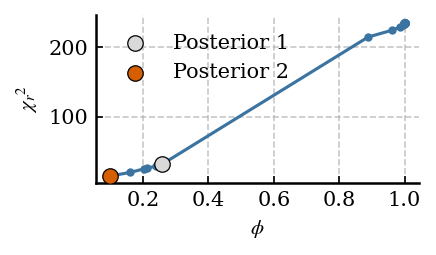

In [2]:
# chi2 vs phi from the NMR ensemble

protein = proteins[0]

# reweighting data NMR
wopt_array = np.load(f'../../DESRES_FOLDING_DATA/{protein}/rewM14DH_scaled/log_lambda_wopt_array.npy')
rewdata = np.loadtxt(f'../../DESRES_FOLDING_DATA/{protein}/rewM14DH_scaled/log_lambda_reweighting_chi2_phi_theta.txt')
phi = rewdata[1,:]
chi2 = rewdata[0,:]

# posterior 1 = elbow
wopt1 = np.load(f'../../DESRES_FOLDING_DATA/{protein}/rewM14DH_scaled/log_lambda_wopt_elbow.npy')
# posterior 2 = final with phi > 0.1
wopt2 = np.load(f'../../DESRES_FOLDING_DATA/{protein}/rewM14DH_scaled/log_lambda_wopt.npy')

# identify the three posterior points
idx_post1 = np.argmin(np.sum((wopt_array - wopt1[None,:])**2, axis=1))
idx_post2 = np.argmin(np.sum((wopt_array - wopt2[None,:])**2, axis=1))

print(f"Posterior 1: phi = {phi[idx_post1]:.4f}, chi2 = {chi2[idx_post1]:.4f}")
print(f"Posterior 2: phi = {phi[idx_post2]:.4f}, chi2 = {chi2[idx_post2]:.4f}")

# colours
COLOR_CURVE = "#3B73A1"
COLOR_POST1 = "#D9D9D9"
COLOR_POST2 = "#D55E00"

# sort by phi for a clean line
order = np.argsort(phi)

fig, ax = plt.subplots(figsize=(3, 1.8))

ax.plot(phi[order], chi2[order], "-o", color=COLOR_CURVE, markersize=3, linewidth=1.5, zorder=2)

# highlight selected posteriors
ax.scatter(phi[idx_post1], chi2[idx_post1], s=55, color=COLOR_POST1, edgecolor="black", linewidth=0.6, label="Posterior 1", zorder=4)
ax.scatter(phi[idx_post2], chi2[idx_post2], s=55, color=COLOR_POST2, edgecolor="black", linewidth=0.6, label="Posterior 2", zorder=4)

ax.set_xlabel(r"$\phi$")
ax.set_ylabel(r"$\chi$$_{r}$$^{2}$")
ax.legend(frameon=False)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(axis="x", which="both", top=False)
ax.tick_params(axis="y", which="both", right=False)

plt.tight_layout()
plt.savefig(outdir+"chi2_vs_phi_NMR.pdf") 
plt.show()

Posterior 1 phi = 0.2569
Posterior 2 phi = 0.1005


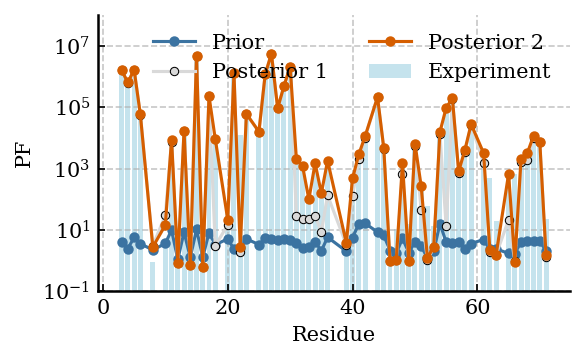

In [3]:
# comparison of NMR protection factors and prior/posterior

protein = proteins[0]

exp = pd.read_csv(f'../../EXP_DATA/PF_Nguyen_2018/{protein}.csv')

# get fopen
fopen = np.load(f'../../DESRES_FOLDING_DATA/{protein}/rewM14DH_scaled/O.npy')
res = np.loadtxt(f'../../DESRES_FOLDING_DATA/{protein}/rewM14DH_scaled/amideresidues.txt').astype(int)
exp_residues = np.loadtxt(f'../../DESRES_FOLDING_DATA/{protein}/rewM14DH_scaled/exp_residues.txt').astype(int)

# indices corresponding to the same common residue set
exp_idxs_comp = np.array([list(res).index(ele) for ele in exp_residues])
exp_idxs_exp = np.array([list(exp['Model_residue']).index(ele) for ele in exp_residues])

# reweighting data
wopt_array = np.load(f'../../DESRES_FOLDING_DATA/{protein}/rewM14DH_scaled/log_lambda_wopt_array.npy')
rewdata = np.loadtxt(f'../../DESRES_FOLDING_DATA/{protein}/rewM14DH_scaled/log_lambda_reweighting_chi2_phi_theta.txt')
phi = rewdata[1,:]

# posterior 1 = elbow
wopt1 = np.load(f'../../DESRES_FOLDING_DATA/{protein}/rewM14DH_scaled/log_lambda_wopt_elbow.npy')

# posterior 2 = final
wopt2 = np.load(f'../../DESRES_FOLDING_DATA/{protein}/rewM14DH_scaled/log_lambda_wopt.npy')

# identify phi values
idx_post1 = np.argmin(np.sum((wopt_array - wopt1[None,:])**2, axis=1))
idx_post2 = np.argmin(np.sum((wopt_array - wopt2[None,:])**2, axis=1))

print(f"Posterior 1 phi = {phi[idx_post1]:.4f}")
print(f"Posterior 2 phi = {phi[idx_post2]:.4f}")

# PFs for all computed amide residues
PFprior = 1 / np.mean(fopen, axis=0)
PF1 = 1 / np.average(fopen, weights=wopt1, axis=0)
PF2 = 1 / np.average(fopen, weights=wopt2, axis=0)

# select the common experimental residues in exactly the same order
plot_res = exp_residues
PFexp = exp['PF'].to_numpy()[exp_idxs_exp]
PFprior_plot = PFprior[exp_idxs_comp]
PF1_plot = PF1[exp_idxs_comp]
PF2_plot = PF2[exp_idxs_comp]

# colours
COLOR_PRIOR = "#3B73A1"
COLOR_POST1 = "#D9D9D9"
COLOR_POST2 = "#D55E00"
COLOR_EXP = "lightblue"

# plot
fig, ax = plt.subplots(figsize=(4,2.5))

ax.bar(plot_res, PFexp, width=0.8, color=COLOR_EXP, edgecolor="none", alpha=0.7, label="Experiment", zorder=1)
ax.plot(plot_res, PFprior_plot, "-o", color=COLOR_PRIOR, markersize=4, linewidth=1.5, label="Prior", zorder=3)
ax.plot(plot_res, PF1_plot, "-o", color=COLOR_POST1, markeredgecolor="black", markeredgewidth=0.5, markersize=4, linewidth=1.5, label=rf"Posterior 1", zorder=4)
ax.plot(plot_res, PF2_plot, "-o", color=COLOR_POST2, markersize=4, linewidth=1.5, label=rf"Posterior 2", zorder=5)

ax.set_yscale("log")
ax.set_xlabel("Residue")
ax.set_ylabel("PF")
ax.set_ylim(1e-1, 1e8)
ax.legend(frameon=False, ncol=2)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(axis="x", which="both", top=False)
ax.tick_params(axis="y", which="both", right=False)

plt.tight_layout()
plt.savefig(outdir+'EXP_vs_CALC_PF_NMR.pdf')
plt.show()

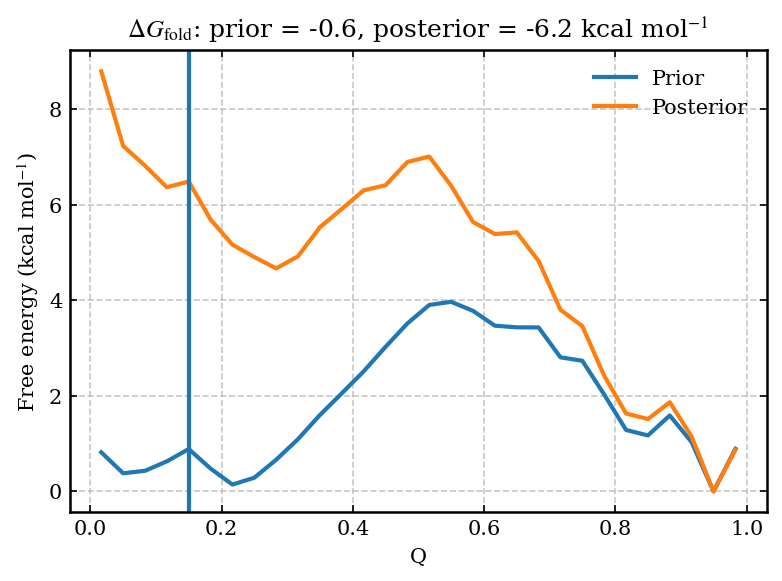

In [2]:
# free energy landscape of folding as a function of Q


nbins = 30

k = 0.008314
T = 303.0
kT = k*T

# get correct traj order
trajs = sorted(find_xtc_filenames(f'../../{ensemble_master_dir}/{protein}/'))

# cut-off for folding
unfolded_cutoff = 0.15

# load Q and frames data - fraction of native contacts
for i, traj in enumerate(trajs):
    if traj == trajs[0]:
        Q = np.loadtxt(f'../../{ensemble_master_dir}/{protein}/native_contacts/Q_{traj}.txt')
    else:
        tmpQ = np.loadtxt(f'../../{ensemble_master_dir}/{protein}/native_contacts/Q_{traj}.txt')
        Q = np.concatenate((Q, tmpQ), axis=0)

w_prior = np.ones(len(Q))/len(Q)
w_post = np.load(f'../../{ensemble_master_dir}/{protein}/rewM14DH_scaled/log_lambda_wopt_elbow.npy')

# calculate folding free energies
folded = np.where(Q > unfolded_cutoff)[0]
unfolded = np.where(Q < unfolded_cutoff)[0]

dG_prior = -kT*np.log(np.sum(w_prior[folded])/np.sum(w_prior[unfolded]))*0.239005736
dG_post = -kT*np.log(np.sum(w_post[folded])/np.sum(w_post[unfolded]))*0.239005736

# use the same bin edges for prior and posterior
bin_edges = np.histogram_bin_edges(Q, bins=nbins)
bin_centers = (bin_edges[:-1] + bin_edges[1:])/2

counts_prior, _ = np.histogram(Q, bins=bin_edges, weights=w_prior)
counts_post, _ = np.histogram(Q, bins=bin_edges, weights=w_post)

p_prior = counts_prior/np.sum(counts_prior)
p_post = counts_post/np.sum(counts_post)

fel_prior = -np.log(p_prior)*kT
fel_post = -np.log(p_post)*kT

fel_prior = (fel_prior - np.nanmin(fel_prior))*0.239005736
fel_post = (fel_post - np.nanmin(fel_post))*0.239005736

plt.plot(bin_centers, fel_prior, label='Prior')
plt.plot(bin_centers, fel_post, label='Posterior')
plt.axvline(unfolded_cutoff)

plt.title(rf'$\Delta G_{{\mathrm{{fold}}}}$: prior = {dG_prior:.1f}, posterior = {dG_post:.1f} kcal mol$^{{-1}}$')
plt.xlabel('Q')
plt.ylabel(r'Free energy (kcal mol$^{-1}$)')
plt.legend()

0.5496590000000001
-6.83
0.16
0.5283433161611474
-4.167413321314722
-4.751445543411707


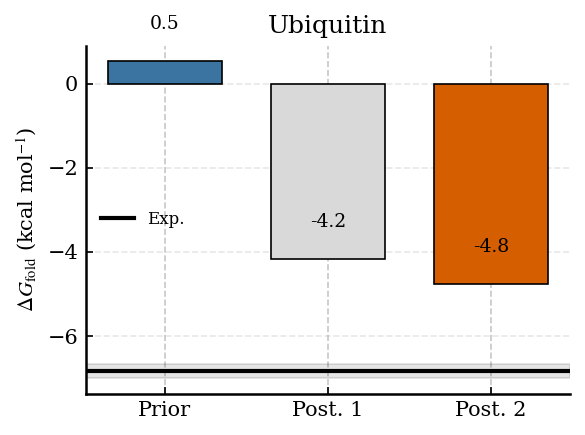

In [3]:
# barplot comparing experimental, prior, posterior 1, and posterior 2 folding free energies

protein = proteins[0]

COLOR3 = "#3B73A1"  # prior
COLOR2 = "#D9D9D9"  # posterior 1: elbow
COLOR1 = "#D55E00"  # posterior 2

# experimental dG
exp_dG, exp_dG_err = np.loadtxt(f'../../ORTHOGONAL_EXP_DATA/{protein}/dG.dat', unpack=True)

w_post1 = np.load(f'../../{ensemble_master_dir}/{protein}/rewM14DH_scaled/log_lambda_wopt_elbow.npy')
w_post2 = np.load(f'../../{ensemble_master_dir}/{protein}/rewM14DH_scaled/log_lambda_wopt.npy')
# prior + posterior 1 (elbow)
_, _, _, _, _, _, dG_prior, dG_post1, _, native_cutoff = compute_free_energy(Q=Q, wopt=w_post1)

# prior + posterior 2 (final)
_, _, _, _, _, _, _, dG_post2, _, native_cutoff = compute_free_energy(Q=Q, wopt=w_post2)

print(native_cutoff)
print(exp_dG)
print(exp_dG_err)
print(dG_prior)
print(dG_post1)
print(dG_post2)

labels = ['Prior', 'Post. 1', 'Post. 2']
values = [dG_prior, dG_post1, dG_post2]
colors = [COLOR3, COLOR2, COLOR1]
x = np.arange(len(labels))

fig, ax = plt.subplots(figsize=(4, 3))

bars = ax.bar(x, values, color=colors, edgecolor='black', linewidth=0.8, width=0.7, zorder=3)

# experimental value as black horizontal line
ax.axhline(exp_dG, color='black', lw=2, zorder=5, label='Exp.')

# optional experimental uncertainty band
ax.axhspan(exp_dG - exp_dG_err, exp_dG + exp_dG_err, color='black', alpha=0.10, zorder=1)

# value labels
for xi, yi in zip(x, values):
    ax.text(xi, yi + 0.08 * (ax.get_ylim()[1] - ax.get_ylim()[0] if ax.get_ylim()[1] > ax.get_ylim()[0] else 1), f'{yi:.1f}', ha='center', va='bottom', fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel(r'$\Delta G_{\mathrm{fold}}$ (kcal mol$^{-1}$)')
ax.set_title(protein)
ax.legend(frameon=False, fontsize=8, loc='best')

ax.tick_params(top=False, right=False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_axisbelow(True)
ax.yaxis.grid(True, linestyle='--', alpha=0.3, zorder=0)

plt.tight_layout()
plt.savefig(outdir+f'{protein}_dG_barplot.pdf', dpi=300)
plt.show()

[0.6645877]
-6.83
0.16
0.5283433161611474
-6.1789918552990395
-6.1262597320297205


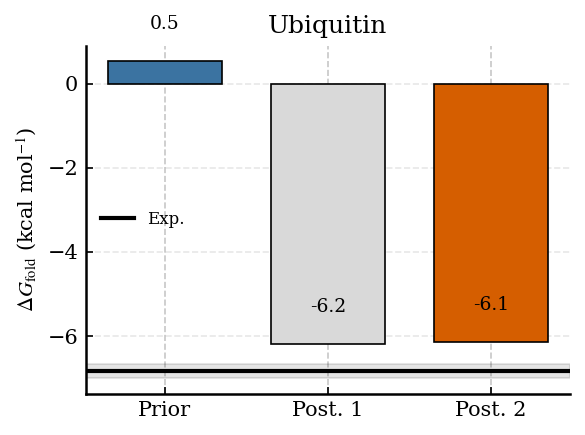

In [4]:
# barplot comparing experimental, prior, posterior 1, and posterior 2 folding free energies

protein = proteins[0]

COLOR3 = "#3B73A1"  # prior
COLOR2 = "#D9D9D9"  # posterior 1: elbow
COLOR1 = "#D55E00"  # posterior 2

# experimental dG
exp_dG, exp_dG_err = np.loadtxt(f'../../ORTHOGONAL_EXP_DATA/{protein}/dG.dat', unpack=True)

w_post1 = np.load(f'../../{ensemble_master_dir}/{protein}/rewM14DH_scaled/log_lambda_wopt_elbow.npy')
w_post2 = np.load(f'../../{ensemble_master_dir}/{protein}/rewM14DH_scaled/log_lambda_wopt.npy')
# prior + posterior 1 (elbow)
_, _, _, _, dG_prior1, dG_post1, _, _, native_cutoff, _ = compute_free_energy(Q=Q, wopt=w_post1, unfolded_cutoff=0.15)

# prior + posterior 2 (final)
_, _, _, _, dG_prior2, dG_post2, _, _, native_cutoff, _ = compute_free_energy(Q=Q, wopt=w_post2, unfolded_cutoff=0.15)

print(native_cutoff)
print(exp_dG)
print(exp_dG_err)
print(dG_prior)
print(dG_post1)
print(dG_post2)

labels = ['Prior', 'Post. 1', 'Post. 2']
values = [dG_prior, dG_post1, dG_post2]
colors = [COLOR3, COLOR2, COLOR1]
x = np.arange(len(labels))

fig, ax = plt.subplots(figsize=(4, 3))

bars = ax.bar(x, values, color=colors, edgecolor='black', linewidth=0.8, width=0.7, zorder=3)

# experimental value as black horizontal line
ax.axhline(exp_dG, color='black', lw=2, zorder=5, label='Exp.')

# optional experimental uncertainty band
ax.axhspan(exp_dG - exp_dG_err, exp_dG + exp_dG_err, color='black', alpha=0.10, zorder=1)

# value labels
for xi, yi in zip(x, values):
    ax.text(xi, yi + 0.08 * (ax.get_ylim()[1] - ax.get_ylim()[0] if ax.get_ylim()[1] > ax.get_ylim()[0] else 1), f'{yi:.1f}', ha='center', va='bottom', fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel(r'$\Delta G_{\mathrm{fold}}$ (kcal mol$^{-1}$)')
ax.set_title(protein)
ax.legend(frameon=False, fontsize=8, loc='best')

ax.tick_params(top=False, right=False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_axisbelow(True)
ax.yaxis.grid(True, linestyle='--', alpha=0.3, zorder=0)

plt.tight_layout()
plt.savefig(outdir+f'{protein}_dG_barplot_U1_cutoff.pdf', dpi=300)
plt.show()

/tmp/ipykernel_1037290/2992187300.py:45: RuntimeWarning: divide by zero encountered in log
  fel_post = -np.log(p_post)*kT


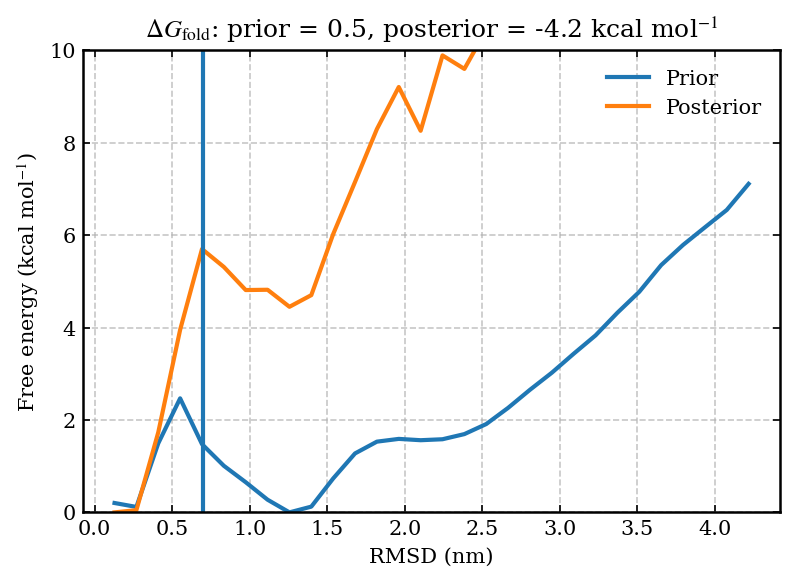

In [5]:
# free energy landscape of folding as a function of rmsd


nbins = 30

k = 0.008314
T = 303.0
kT = k*T

# get correct traj order
trajs = sorted(find_xtc_filenames(f'../../{ensemble_master_dir}/{protein}/'))

# cut-off for folding
folded_cutoff = 0.7

# load rmsd and frames data
for traj in trajs:
    if traj == trajs[0]:
        rmsd = np.loadtxt(f'../../{ensemble_master_dir}/{protein}/rmsd_data/rmsd_{traj}.xvg', skiprows=18)[:,1]
    else:
        tmprmsd = np.loadtxt(f'../../{ensemble_master_dir}/{protein}/rmsd_data/rmsd_{traj}.xvg', skiprows=18)[:,1]
        rmsd = np.concatenate((rmsd, tmprmsd), axis=0)

w_prior = np.ones(len(rmsd))/len(rmsd)
w_post = np.load(f'../../{ensemble_master_dir}/{protein}/rewM14DH_scaled/log_lambda_wopt_elbow.npy')

# calculate folding free energies
folded = np.where(rmsd < folded_cutoff)[0]
unfolded = np.where(rmsd > folded_cutoff)[0]

dG_prior = -kT*np.log(np.sum(w_prior[folded])/np.sum(w_prior[unfolded]))*0.239005736
dG_post = -kT*np.log(np.sum(w_post[folded])/np.sum(w_post[unfolded]))*0.239005736

# use same bin edges for prior and posterior
bin_edges = np.histogram_bin_edges(rmsd, bins=nbins)
bin_centers = (bin_edges[:-1] + bin_edges[1:])/2

counts_prior, _ = np.histogram(rmsd, bins=bin_edges, weights=w_prior)
counts_post, _ = np.histogram(rmsd, bins=bin_edges, weights=w_post)

p_prior = counts_prior/np.sum(counts_prior)
p_post = counts_post/np.sum(counts_post)

fel_prior = -np.log(p_prior)*kT
fel_post = -np.log(p_post)*kT

fel_prior = (fel_prior - np.nanmin(fel_prior))*0.239005736
fel_post = (fel_post - np.nanmin(fel_post))*0.239005736

plt.plot(bin_centers, fel_prior, label='Prior')
plt.plot(bin_centers, fel_post, label='Posterior')
plt.ylim(0,10)
plt.axvline(0.7)

plt.title(rf'$\Delta G_{{\mathrm{{fold}}}}$: prior = {dG_prior:.1f}, posterior = {dG_post:.1f} kcal mol$^{{-1}}$')
plt.xlabel('RMSD (nm)')
plt.ylabel(r'Free energy (kcal mol$^{-1}$)')
plt.legend()

In [7]:
len(rmsd)

6735169

/tmp/ipykernel_1037290/3286864835.py:81: UserWarning: The following kwargs were not used by contour: 'rasterized'
  ax.contour(Xc, Yc, F_post, levels=levels, linewidths=0.8, colors='black', rasterized=True)


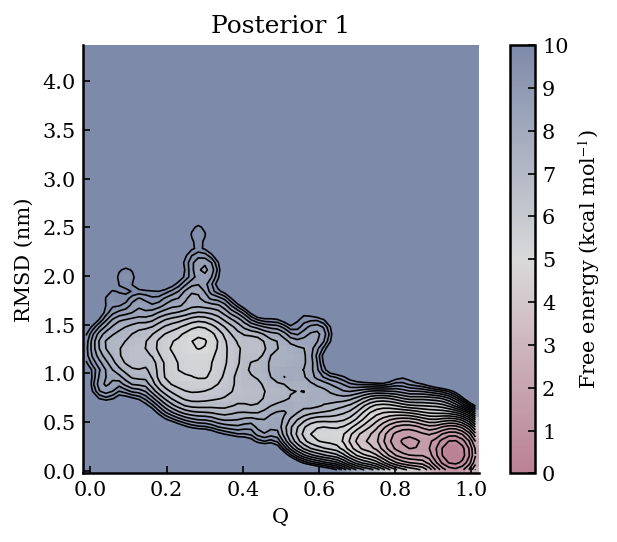

In [8]:
# FEL of posterior 1 (elbow) as a function of Q and RMSD
# with mild Gaussian smoothing of the 2D probability histogram

from matplotlib.colors import LinearSegmentedColormap
from scipy.ndimage import gaussian_filter


protein = proteins[0]
synframes = 0
nbins = 60
max_energy = 10.0   # kcal mol^-1; start with 5.0 or 6.0
sigma = 1.0     # Gaussian smoothing in bin units

# posterior 1 weights
wopt = np.load(f'../../{ensemble_master_dir}/{protein}/rewM14DH_scaled/log_lambda_wopt_elbow.npy')

# optional: drop synthetic frames at the end if present
Q_use = np.asarray(Q, dtype=float)
rmsd_use = np.asarray(rmsd, dtype=float)
if synframes > 0:
    Q_use = Q_use[:-synframes]
    rmsd_use = rmsd_use[:-synframes]
    wopt = wopt[:-synframes]

# sanity check
assert len(Q_use) == len(rmsd_use) == len(wopt), "Q, rmsd, and wopt must have the same length"

# normalize posterior weights
w_post = wopt / np.sum(wopt)

# shared binning
xmin, xmax = np.min(Q_use), np.max(Q_use)
ymin, ymax = np.min(rmsd_use), np.max(rmsd_use)
xpad = 0.02 * (xmax - xmin)
ypad = 0.02 * (ymax - ymin)
xbins = np.linspace(xmin - xpad, xmax + xpad, nbins + 1)
ybins = np.linspace(ymin - ypad, ymax + ypad, nbins + 1)

# weighted 2D histogram
H_post, xedges, yedges = np.histogram2d(Q_use, rmsd_use, bins=[xbins, ybins], weights=w_post)

# smooth histogram for visualization
H_post_smooth = gaussian_filter(H_post, sigma=sigma, mode='constant', cval=0.0)
H_post_smooth = H_post_smooth / np.sum(H_post_smooth)

# convert histogram to FEL
kB = 0.0019872041  # kcal mol^-1 K^-1
T = 303.0

def hist_to_fel(H, kB=0.0019872041, T=293.0):
    F = np.full_like(H, np.nan, dtype=float)
    mask = H > 0
    F[mask] = -kB * T * np.log(H[mask])
    F -= np.nanmin(F)
    return F

F_post = hist_to_fel(H_post_smooth, kB=kB, T=T)

# bin centers for contours
xc = 0.5 * (xedges[:-1] + xedges[1:])
yc = 0.5 * (yedges[:-1] + yedges[1:])
Xc, Yc = np.meshgrid(xc, yc, indexing='ij')

# colour scale: min -> middle -> max_energy
middle = max_energy / 2
cmap = LinearSegmentedColormap.from_list('fel_cmap', [(0.0, "#BB8194"), (0.5, "#D9D9D9"), (1.0, "#7D8AA9")])

# fill any remaining NaNs with max_energy for plotting only
F_plot = np.where(np.isnan(F_post), max_energy, F_post)
F_plot = np.minimum(F_plot, max_energy)

# contour levels
levels = np.arange(0.5, max_energy + 0.001, 0.5)
levels = levels[levels <= np.nanmax(F_post)]

# plotting
fig, ax = plt.subplots(figsize=(4,3.5), constrained_layout=True)

pcm = ax.pcolormesh(xedges, yedges, F_plot.T, shading='auto', cmap=cmap, vmin=0, vmax=max_energy, rasterized=True)
if len(levels) > 0:
    ax.contour(Xc, Yc, F_post, levels=levels, linewidths=0.8, colors='black', rasterized=True)

ax.set_title('Posterior 1')
ax.set_xlabel('Q')
ax.set_ylabel('RMSD (nm)')

ax.tick_params(axis='both', which='both', top=False, right=False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

cbar = fig.colorbar(pcm, ax=ax, pad=0.02)
cbar.set_label(r'Free energy (kcal mol$^{-1}$)')
cbar.set_ticks(np.arange(0, max_energy + 1, 1))

plt.savefig(outdir+f'{protein}_Q_RMSD_FEL_post1_smoothed.pdf', dpi=300)
plt.show()

/tmp/ipykernel_1037290/2896607884.py:82: UserWarning: The following kwargs were not used by contour: 'rasterized'
  ax.contour(Xc, Yc, F_post, levels=levels, linewidths=0.8, colors='black', rasterized=True)


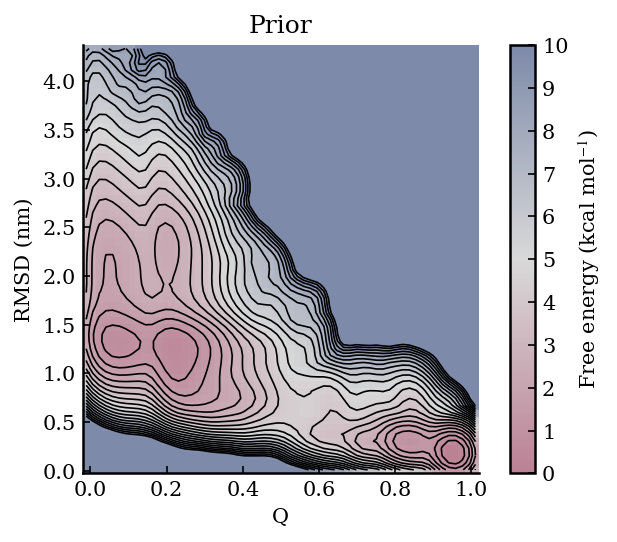

In [9]:
# FEL of prior as a function of Q and RMSD
# with mild Gaussian smoothing of the 2D probability histogram

from matplotlib.colors import LinearSegmentedColormap
from scipy.ndimage import gaussian_filter


protein = proteins[0]
synframes = 0
nbins = 60
max_energy = 10.0   # kcal mol^-1; start with 5.0 or 6.0
sigma = 1.0     # Gaussian smoothing in bin units

# prior weights
wopt = np.load(f'../../{ensemble_master_dir}/{protein}/rewM14DH_scaled/log_lambda_wopt_elbow.npy')
wopt = np.ones(len(wopt))/len(wopt)

# optional: drop synthetic frames at the end if present
Q_use = np.asarray(Q, dtype=float)
rmsd_use = np.asarray(rmsd, dtype=float)
if synframes > 0:
    Q_use = Q_use[:-synframes]
    rmsd_use = rmsd_use[:-synframes]
    wopt = wopt[:-synframes]

# sanity check
assert len(Q_use) == len(rmsd_use) == len(wopt), "Q, rmsd, and wopt must have the same length"

# normalize prior weights
w_post = wopt / np.sum(wopt)

# shared binning
xmin, xmax = np.min(Q_use), np.max(Q_use)
ymin, ymax = np.min(rmsd_use), np.max(rmsd_use)
xpad = 0.02 * (xmax - xmin)
ypad = 0.02 * (ymax - ymin)
xbins = np.linspace(xmin - xpad, xmax + xpad, nbins + 1)
ybins = np.linspace(ymin - ypad, ymax + ypad, nbins + 1)

# weighted 2D histogram
H_post, xedges, yedges = np.histogram2d(Q_use, rmsd_use, bins=[xbins, ybins], weights=w_post)

# smooth histogram for visualization
H_post_smooth = gaussian_filter(H_post, sigma=sigma, mode='constant', cval=0.0)
H_post_smooth = H_post_smooth / np.sum(H_post_smooth)

# convert histogram to FEL
kB = 0.0019872041  # kcal mol^-1 K^-1
T = 303.0

def hist_to_fel(H, kB=0.0019872041, T=293.0):
    F = np.full_like(H, np.nan, dtype=float)
    mask = H > 0
    F[mask] = -kB * T * np.log(H[mask])
    F -= np.nanmin(F)
    return F

F_post = hist_to_fel(H_post_smooth, kB=kB, T=T)

# bin centers for contours
xc = 0.5 * (xedges[:-1] + xedges[1:])
yc = 0.5 * (yedges[:-1] + yedges[1:])
Xc, Yc = np.meshgrid(xc, yc, indexing='ij')

# colour scale: min -> middle -> max_energy
middle = max_energy / 2
cmap = LinearSegmentedColormap.from_list('fel_cmap', [(0.0, "#BB8194"), (0.5, "#D9D9D9"), (1.0, "#7D8AA9")])

# fill any remaining NaNs with max_energy for plotting only
F_plot = np.where(np.isnan(F_post), max_energy, F_post)
F_plot = np.minimum(F_plot, max_energy)

# contour levels
levels = np.arange(0.5, max_energy + 0.001, 0.5)
levels = levels[levels <= np.nanmax(F_post)]

# plotting
fig, ax = plt.subplots(figsize=(4,3.5), constrained_layout=True)

pcm = ax.pcolormesh(xedges, yedges, F_plot.T, shading='auto', cmap=cmap, vmin=0, vmax=max_energy, rasterized=True)
if len(levels) > 0:
    ax.contour(Xc, Yc, F_post, levels=levels, linewidths=0.8, colors='black', rasterized=True)

ax.set_title('Prior')
ax.set_xlabel('Q')
ax.set_ylabel('RMSD (nm)')

ax.tick_params(axis='both', which='both', top=False, right=False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

cbar = fig.colorbar(pcm, ax=ax, pad=0.02)
cbar.set_label(r'Free energy (kcal mol$^{-1}$)')
cbar.set_ticks(np.arange(0, max_energy + 1, 1))

plt.savefig(outdir+f'{protein}_Q_RMSD_FEL_prior_smoothed.pdf', dpi=300)
plt.show()

Found 4 local minima:
 1: Q = 0.959  RMSD = 0.156 nm  F = 0.000 kcal/mol
 2: Q = 0.837  RMSD = 0.303 nm  F = 1.347 kcal/mol
 3: Q = 0.283  RMSD = 1.329 nm  F = 4.906 kcal/mol
 4: Q = 0.612  RMSD = 0.376 nm  F = 5.238 kcal/mol


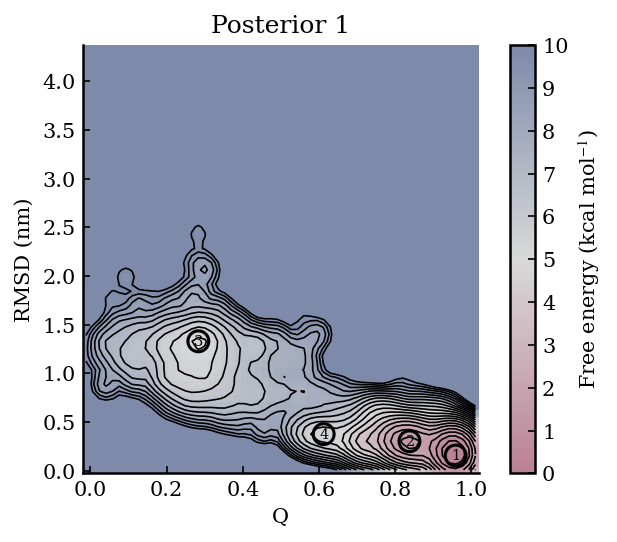

In [20]:
# FEL of posterior 1 (elbow) as a function of Q and RMSD
# with mild Gaussian smoothing of the 2D probability histogram
# local minima are detected on the smoothed FEL and marked on the plot

from matplotlib.colors import LinearSegmentedColormap
from scipy.ndimage import gaussian_filter, minimum_filter

protein = proteins[0]
synframes = 0
nbins = 60
max_energy = 10.0
sigma = 1.0
minima_neighborhood = 3
minima_max_energy = 6.0

# posterior 1 weights
wopt = np.load(f'../../{ensemble_master_dir}/{protein}/rewM14DH_scaled/log_lambda_wopt_elbow.npy')

# optional: drop synthetic frames at the end if present
Q_use = np.asarray(Q, dtype=float)
rmsd_use = np.asarray(rmsd, dtype=float)

if synframes > 0:
    Q_use = Q_use[:-synframes]
    rmsd_use = rmsd_use[:-synframes]
    wopt = wopt[:-synframes]

# sanity check
assert len(Q_use) == len(rmsd_use) == len(wopt), "Q, rmsd, and wopt must have the same length"

# normalize posterior weights
w_post = wopt / np.sum(wopt)

# shared binning
xmin, xmax = np.min(Q_use), np.max(Q_use)
ymin, ymax = np.min(rmsd_use), np.max(rmsd_use)
xpad = 0.02 * (xmax - xmin)
ypad = 0.02 * (ymax - ymin)
xbins = np.linspace(xmin - xpad, xmax + xpad, nbins + 1)
ybins = np.linspace(ymin - ypad, ymax + ypad, nbins + 1)

# weighted 2D histogram
H_post, xedges, yedges = np.histogram2d(Q_use, rmsd_use, bins=[xbins, ybins], weights=w_post)

# smooth histogram for visualization
H_post_smooth = gaussian_filter(H_post, sigma=sigma, mode='constant', cval=0.0)
H_post_smooth = H_post_smooth / np.sum(H_post_smooth)

# convert histogram to FEL
kB = 0.0019872041
T = 303.0

def hist_to_fel(H, kB=0.0019872041, T=293.0):
    F = np.full_like(H, np.nan, dtype=float)
    mask = H > 0
    F[mask] = -kB * T * np.log(H[mask])
    F -= np.nanmin(F)
    return F

F_post = hist_to_fel(H_post_smooth, kB=kB, T=T)

# bin centers for contours
xc = 0.5 * (xedges[:-1] + xedges[1:])
yc = 0.5 * (yedges[:-1] + yedges[1:])
Xc, Yc = np.meshgrid(xc, yc, indexing='ij')

# ------------------------------------------------------------------
# identify local minima
# ------------------------------------------------------------------

F_minima = np.where(np.isfinite(F_post), F_post, np.inf)
local_min = F_minima == minimum_filter(F_minima, size=minima_neighborhood, mode='constant', cval=np.inf)
local_min &= np.isfinite(F_post)
local_min &= F_post <= minima_max_energy

# ignore outermost bins
local_min[0,:] = False
local_min[-1,:] = False
local_min[:,0] = False
local_min[:,-1] = False

# minima coordinates and energies
min_i, min_j = np.where(local_min)
min_Q = xc[min_i]
min_rmsd = yc[min_j]
min_F = F_post[min_i, min_j]

# sort minima by increasing free energy
order = np.argsort(min_F)
min_Q = min_Q[order]
min_rmsd = min_rmsd[order]
min_F = min_F[order]

print(f'Found {len(min_Q)} local minima:')

for i, (q, r, F) in enumerate(zip(min_Q, min_rmsd, min_F), start=1):
    print(f'{i:2d}: Q = {q:.3f}  RMSD = {r:.3f} nm  F = {F:.3f} kcal/mol')

# colour scale
cmap = LinearSegmentedColormap.from_list('fel_cmap', [(0.0, "#BB8194"), (0.5, "#D9D9D9"), (1.0, "#7D8AA9")])

# fill remaining NaNs with max_energy for plotting only
F_plot = np.where(np.isnan(F_post), max_energy, F_post)
F_plot = np.minimum(F_plot, max_energy)

# contour levels
levels = np.arange(0.5, max_energy + 0.001, 0.5)
levels = levels[levels <= np.nanmax(F_post)]

# plotting
fig, ax = plt.subplots(figsize=(4,3.5), constrained_layout=True)

pcm = ax.pcolormesh(xedges, yedges, F_plot.T, shading='auto', cmap=cmap, vmin=0, vmax=max_energy, rasterized=True)

if len(levels) > 0:
    ax.contour(Xc, Yc, F_post, levels=levels, linewidths=0.8, colors='black')

# mark local minima
ax.scatter(min_Q, min_rmsd, s=100, facecolors='none', edgecolors='black', linewidths=1.5, zorder=30)

# number local minima
for i, (q, r) in enumerate(zip(min_Q, min_rmsd), start=1):
    ax.text(q, r, str(i), ha='center', va='center', fontsize=7, zorder=31)

ax.set_title('Posterior 1')
ax.set_xlabel('Q')
ax.set_ylabel('RMSD (nm)')

ax.tick_params(axis='both', which='both', top=False, right=False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

cbar = fig.colorbar(pcm, ax=ax, pad=0.02)
cbar.set_label(r'Free energy (kcal mol$^{-1}$)')
cbar.set_ticks(np.arange(0, max_energy + 1, 1))

plt.savefig(outdir+f'{protein}_Q_RMSD_FEL_post1_smoothed_minima.pdf', dpi=300)
plt.show()

In [21]:
# extract representative structures for each Q-RMSD FEL minimum
# for each minimum:
# 1) find the n_candidates closest frames in Q-RMSD space
# 2) rank those candidates by distance from the minimum and posterior weight
# 3) select the top n_models and save them as PDB files

import os
import mdtraj as md
import numpy as np
from scipy.stats import rankdata

protein = proteins[0]
n_models = 10
n_candidates = 100

# output directory
rep_dir = 'plots_Ubq_desres/structures_Q_RMSD/'
os.makedirs(rep_dir, exist_ok=True)

# trajectories in exactly the same order as Q/rmsd/reweighting
trajs = sorted(find_xtc_filenames(f'../../{ensemble_master_dir}/{protein}/'))

# posterior weights
wopt = np.load(f'../../{ensemble_master_dir}/{protein}/rewM14DH_scaled/log_lambda_wopt_elbow.npy')

# use the same arrays as in the FEL
Q_use = np.asarray(Q, dtype=float)
rmsd_use = np.asarray(rmsd, dtype=float)

if synframes > 0:
    Q_use = Q_use[:-synframes]
    rmsd_use = rmsd_use[:-synframes]
    wopt = wopt[:-synframes]

assert len(Q_use) == len(rmsd_use) == len(wopt), f"Q, RMSD, and wopt must have the same length: {len(Q_use)}, {len(rmsd_use)}, {len(wopt)}"

# normalize posterior weights
w_post = wopt / np.sum(wopt)

# ------------------------------------------------------------------
# build global frame index -> trajectory/local frame mapping
# ------------------------------------------------------------------

frame_to_traj = np.empty(len(Q_use), dtype=int)
frame_to_local = np.empty(len(Q_use), dtype=int)

global_start = 0

for traj_idx, traj in enumerate(trajs):
    traj_path = f'../../{ensemble_master_dir}/{protein}/{traj}'

    with md.open(traj_path) as f:
        n_frames = len(f)

    global_stop = global_start + n_frames

    if global_stop > len(Q_use):
        global_stop = len(Q_use)
        n_frames = global_stop - global_start

    if n_frames <= 0:
        break

    frame_to_traj[global_start:global_stop] = traj_idx
    frame_to_local[global_start:global_stop] = np.arange(n_frames)

    global_start = global_stop

    if global_start == len(Q_use):
        break

assert global_start == len(Q_use), f"Trajectory frames account for {global_start} frames, but Q/RMSD arrays contain {len(Q_use)} frames"

# ------------------------------------------------------------------
# extract representative structures for each FEL minimum
# ------------------------------------------------------------------

for imin, (minimum_Q, minimum_rmsd, minimum_F) in enumerate(zip(min_Q, min_rmsd, min_F), start=1):

    # Euclidean distance from minimum in Q-RMSD space
    distance = np.sqrt((Q_use - minimum_Q)**2 + (rmsd_use - minimum_rmsd)**2)

    # closest local structures
    candidates = np.argsort(distance)[:min(n_candidates, len(distance))]

    candidate_distance = distance[candidates]
    candidate_weight = w_post[candidates]

    # rank 1 = closest
    distance_rank = rankdata(candidate_distance, method='ordinal')

    # rank 1 = highest posterior weight
    weight_rank = rankdata(-candidate_weight, method='ordinal')

    # equal contribution from FEL-space distance and posterior weight
    combined_rank = distance_rank + weight_rank

    # top representative structures
    selected_local = np.argsort(combined_rank)[:min(n_models, len(candidates))]

    # output directory for this minimum
    minimum_dir = os.path.join(rep_dir, f'minimum_{imin:02d}')
    os.makedirs(minimum_dir, exist_ok=True)

    print(f'\nMinimum {imin}: Q = {minimum_Q:.3f}, RMSD = {minimum_rmsd:.3f} nm, F = {minimum_F:.3f} kcal/mol')

    info = []

    for rank, candidate_idx in enumerate(selected_local, start=1):
        global_idx = candidates[candidate_idx]
        traj_idx = frame_to_traj[global_idx]
        local_frame = frame_to_local[global_idx]
        traj = trajs[traj_idx]
        traj_path = f'../../{ensemble_master_dir}/{protein}/{traj}'

        # load selected frame
        structure = md.load_frame(traj_path, int(local_frame), top=f'../../{ensemble_master_dir}/{protein}/topology.pdb')

        # save PDB
        outfile = os.path.join(minimum_dir, f'model_{rank:02d}.pdb')
        structure.save_pdb(outfile)

        info.append([rank, global_idx, traj_idx, local_frame, Q_use[global_idx], rmsd_use[global_idx], distance[global_idx], w_post[global_idx], distance_rank[candidate_idx], weight_rank[candidate_idx], combined_rank[candidate_idx]])

        print(f'{rank:2d}: frame {global_idx:7d}  traj {traj_idx:3d}  local frame {local_frame:7d}  Q = {Q_use[global_idx]:.3f}  RMSD = {rmsd_use[global_idx]:.3f}  distance = {distance[global_idx]:.4f}  weight = {w_post[global_idx]:.3e}')

    # save metadata
    np.savetxt(
        os.path.join(minimum_dir, 'models.dat'),
        np.asarray(info),
        header='rank global_frame traj_index local_frame Q RMSD distance posterior_weight distance_rank weight_rank combined_rank',
        fmt=['%d', '%d', '%d', '%d', '%.6f', '%.6f', '%.6f', '%.8e', '%d', '%d', '%d']
    )


Minimum 1: Q = 0.959, RMSD = 0.156 nm, F = 0.000 kcal/mol
 1: frame 2112438  traj 211  local frame    4811  Q = 0.959  RMSD = 0.156  distance = 0.0001  weight = 6.708e-07
 2: frame 6066592  traj 608  local frame    9314  Q = 0.959  RMSD = 0.156  distance = 0.0001  weight = 6.836e-07
 3: frame 2199588  traj 220  local frame    1961  Q = 0.959  RMSD = 0.156  distance = 0.0002  weight = 6.759e-07
 4: frame 1790605  traj 179  local frame    2978  Q = 0.959  RMSD = 0.156  distance = 0.0002  weight = 6.986e-07
 5: frame 5146674  traj 516  local frame    8236  Q = 0.959  RMSD = 0.157  distance = 0.0002  weight = 7.003e-07
 6: frame 3873641  traj 388  local frame    7792  Q = 0.959  RMSD = 0.157  distance = 0.0002  weight = 6.721e-07
 7: frame 2033906  traj 203  local frame    6279  Q = 0.959  RMSD = 0.156  distance = 0.0001  weight = 6.640e-07
 8: frame 5046421  traj 506  local frame    7983  Q = 0.959  RMSD = 0.156  distance = 0.0001  weight = 6.610e-07
 9: frame 2001725  traj 200  local fr

Broadened Q ranges of 2D FEL minima:
 1: Q = 0.899-0.999  center = 0.959  RMSD = 0.156 nm  F = 0.000 kcal/mol
 2: Q = 0.777-0.897  center = 0.837  RMSD = 0.303 nm  F = 1.347 kcal/mol
 3: Q = 0.223-0.343  center = 0.283  RMSD = 1.329 nm  F = 4.906 kcal/mol
 4: Q = 0.552-0.672  center = 0.612  RMSD = 0.376 nm  F = 5.238 kcal/mol


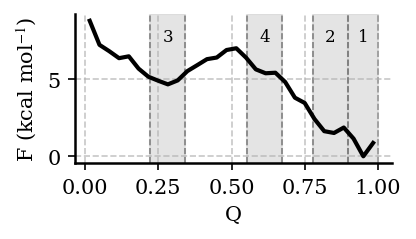

In [30]:
# plot 1D FEL
# free energy landscape of folding as a function of Q
# highlight broader Q regions around each state/minimum

nbins = 30

k = 0.008314
T = 303.0
kT = k * T
kj_to_kcal = 0.239005736

COLOR_POST = "black"

# make state regions broader on the 1D plot
state_halfwidth = 0.06

# get correct traj order
trajs = sorted(find_xtc_filenames(f'../../{ensemble_master_dir}/{protein}/'))

# load Q and frames data - fraction of native contacts
Q = []

for traj in trajs:
    tmpQ = np.loadtxt(f'../../{ensemble_master_dir}/{protein}/native_contacts/Q_{traj}.txt')
    Q.append(tmpQ)

Q = np.concatenate(Q)

w_post = np.load('../../DESRES_FOLDING_DATA/Ubiquitin/rewM14DH_scaled/log_lambda_wopt_elbow.npy')

# calculate posterior FEL
bin_edges = np.histogram_bin_edges(Q, bins=nbins)
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

counts_post, _ = np.histogram(Q, bins=bin_edges, weights=w_post)
p_post = counts_post / np.sum(counts_post)

fel_post = np.full_like(p_post, np.nan, dtype=float)
valid = p_post > 0
fel_post[valid] = -np.log(p_post[valid]) * kT
fel_post = (fel_post - np.nanmin(fel_post)) * kj_to_kcal

# ------------------------------------------------------------------
# broader Q ranges around the 2D FEL minima
# assumes min_Q, min_rmsd, min_F, min_i are already available from
# the previous 2D FEL cell and sorted consistently
# ------------------------------------------------------------------

state_Q_low = np.maximum(min_Q - state_halfwidth, bin_edges[0])
state_Q_high = np.minimum(min_Q + state_halfwidth, bin_edges[-1])

print('Broadened Q ranges of 2D FEL minima:')

for i, (qlo, qhi, q, r, F) in enumerate(zip(state_Q_low, state_Q_high, min_Q, min_rmsd, min_F), start=1):
    print(f'{i:2d}: Q = {qlo:.3f}-{qhi:.3f}  center = {q:.3f}  RMSD = {r:.3f} nm  F = {F:.3f} kcal/mol')

# plot
fig, ax = plt.subplots(figsize=(3.0, 1.7))

ax.plot(bin_centers, fel_post, color=COLOR_POST, lw=2, zorder=10)

# highlight broader state regions
for i, (qlo, qhi) in enumerate(zip(state_Q_low, state_Q_high), start=1):
    ax.axvspan(qlo, qhi, color="0.85", alpha=0.7, zorder=0)
    ax.axvline(qlo, color="0.5", ls="--", lw=0.8, zorder=1)
    ax.axvline(qhi, color="0.5", ls="--", lw=0.8, zorder=1)

ymax = np.nanmax(fel_post)

for i, (qlo, qhi) in enumerate(zip(state_Q_low, state_Q_high), start=1):
    ax.text(0.5 * (qlo + qhi), ymax * 0.95, str(i), ha="center", va="top", fontsize=8)

ax.set_xlabel("Q")
ax.set_ylabel(r"F (kcal mol$^{-1}$)")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(direction="out", top=False, right=False)

plt.tight_layout()
plt.savefig(outdir + f'posterior1_fel_1D_Q_minima.pdf', bbox_inches="tight")
plt.show()

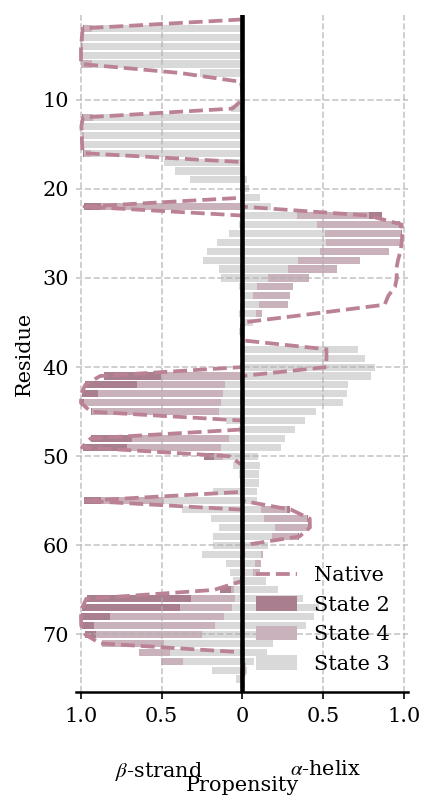

In [ ]:

# secondary-structure propensity for the four Q states
# beta to the left, alpha to the right
# native state (state 1) shown as dashed lines
# other states shown as increasingly darker bars in order of increasing Q

dssp = np.load('../../DESRES_FOLDING_DATA/Ubiquitin/dssp_all_trajs.npy')

# Function to calculate per-residue helicity per frame
def dssp_to_helicity(dssp_lines):
    """
    Convert DSSP strings into a binary helicity matrix.
    
    Parameters
    ----------
    dssp_lines : list of str
        Each entry corresponds to one frame.
        Each string is the DSSP assignment per residue for that frame.
    
    Returns
    -------
    helicity : np.ndarray
        Array of shape (n_frames, n_residues).
        1 = helix ('H', 'G', 'I'), 0 = non-helix.
    """
    helix_codes = {'H', 'G', 'I'}
    
    n_frames = len(dssp_lines)
    n_residues = len(dssp_lines[0])
    
    helicity = np.zeros((n_frames, n_residues), dtype=int)
    
    for i, line in enumerate(dssp_lines):
        helicity[i, :] = [1 if c in helix_codes else 0 for c in line]
    
    return helicity

# Function to calculate per-residue helicity per frame
def dssp_to_strand(dssp_lines):
    """
    same thing for beta strand
    """
    strand_codes = {'E', 'B'}
    
    n_frames = len(dssp_lines)
    n_residues = len(dssp_lines[0])
    
    strandicity = np.zeros((n_frames, n_residues), dtype=int)
    
    for i, line in enumerate(dssp_lines):
        strandicity[i, :] = [1 if c in strand_codes else 0 for c in line]
    
    return strandicity

# calculate per-frame secondary-structure assignments
helicity = dssp_to_helicity(dssp)
strand = dssp_to_strand(dssp)

# residue axis
residues = np.arange(1, helicity.shape[1] + 1)

# posterior weights
wopt = np.load('../../DESRES_FOLDING_DATA/Ubiquitin/rewM14DH_scaled/log_lambda_wopt_elbow.npy')

# state definitions from the broadened Q ranges
mask_S3 = (Q >= 0.223) & (Q <= 0.343)   # lowest Q
mask_S4 = (Q >= 0.552) & (Q <= 0.672)
mask_S2 = (Q > 0.777) & (Q <= 0.900)
mask_N  = (Q > 0.900) & (Q <= 1.000)   # native state = state 1


# weighted propensities
alpha_S3 = np.average(helicity[mask_S3], axis=0, weights=wopt[mask_S3])
beta_S3 = np.average(strand[mask_S3], axis=0, weights=wopt[mask_S3])

alpha_S4 = np.average(helicity[mask_S4], axis=0, weights=wopt[mask_S4])
beta_S4 = np.average(strand[mask_S4], axis=0, weights=wopt[mask_S4])

alpha_S2 = np.average(helicity[mask_S2], axis=0, weights=wopt[mask_S2])
beta_S2 = np.average(strand[mask_S2], axis=0, weights=wopt[mask_S2])

alpha_N = np.average(helicity[mask_N], axis=0, weights=wopt[mask_N])
beta_N = np.average(strand[mask_N], axis=0, weights=wopt[mask_N])



# colours
COLOR_S2 = "#A97F90"
COLOR_S4 = "#C9B2BB"
COLOR_S3 = "#D9D9D9"
COLOR_N = "#BB8194"

# plot
fig, ax = plt.subplots(figsize=(3.0, 5.5))

# overlaid bars: background -> foreground
ax.barh(residues, -beta_S2, height=0.8, color=COLOR_S2, edgecolor="none", label="State 2")
ax.barh(residues,  alpha_S2, height=0.8, color=COLOR_S2, edgecolor="none")

ax.barh(residues, -beta_S4, height=0.8, color=COLOR_S4, edgecolor="none", label="State 4")
ax.barh(residues,  alpha_S4, height=0.8, color=COLOR_S4, edgecolor="none")

ax.barh(residues, -beta_S3, height=0.8, color=COLOR_S3, edgecolor="none", label="State 3")
ax.barh(residues,  alpha_S3, height=0.8, color=COLOR_S3, edgecolor="none")

# native state as dashed lines
ax.plot(-beta_N, residues, ls="--", lw=1.8, color=COLOR_N, label="Native")
ax.plot(alpha_N, residues, ls="--", lw=1.8, color=COLOR_N)

# thick central axis at x = 0
ax.axvline(0, color="k", lw=2.2)

# limits
ax.set_xlim(-1.03, 1.03)
ax.set_ylim(0.5, len(residues) + 0.5)
ax.invert_yaxis()

# y-axis label
ax.set_ylabel("Residue")

# x ticks
ax.set_xticks([-1.0, -0.5, 0.0, 0.5, 1.0])
ax.set_xticklabels(["1.0", "0.5", "0", "0.5", "1.0"])

# x-axis labels
ax.set_xlabel("Propensity", labelpad=24)

ax.text(0.25, -0.10, r"$\beta$-strand", transform=ax.transAxes, ha="center", va="top")
ax.text(0.75, -0.10, r"$\alpha$-helix", transform=ax.transAxes, ha="center", va="top")

# y ticks: every 10 residues
yticks = np.arange(0, len(residues) + 1, 10)
yticks = yticks[yticks > 0]
ax.set_yticks(yticks)
ax.set_yticklabels(yticks)

# styling
ax.spines["left"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["top"].set_visible(False)
ax.tick_params(axis="y", left=False, right=False, length=0)
ax.tick_params(axis="x", direction="out", top=False, right=False)

ax.legend(frameon=False, loc="lower right")

plt.tight_layout()
plt.savefig(outdir+'state_SS_propensities_overlay.pdf')
plt.show()

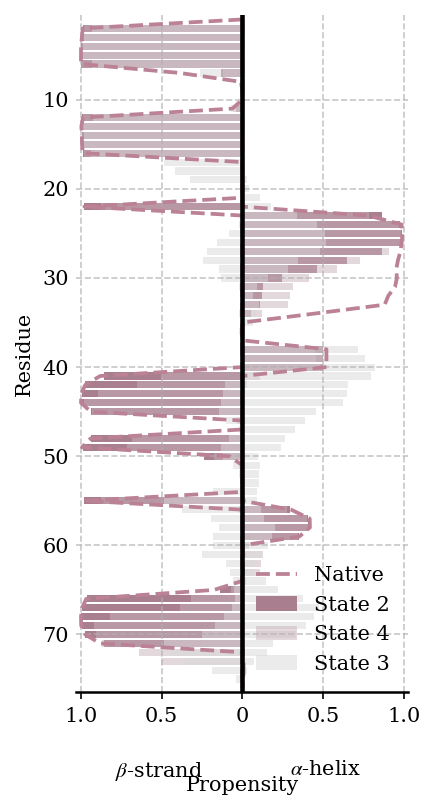

In [ ]:
# colours
COLOR_S2 = "#A97F90"
COLOR_S4 = "#C9B2BB"
COLOR_S3 = "#D9D9D9"
COLOR_N = "#BB8194"

# plot
fig, ax = plt.subplots(figsize=(3.0, 5.5))

# overlaid bars: background -> foreground
ax.barh(residues, -beta_S2, height=0.8, color=COLOR_S2, edgecolor="none", label="State 2")
ax.barh(residues,  alpha_S2, height=0.8, color=COLOR_S2, edgecolor="none")

ax.barh(residues, -beta_S4, height=0.8, color=COLOR_S4, edgecolor="none", label="State 4", alpha=0.5)
ax.barh(residues,  alpha_S4, height=0.8, color=COLOR_S4, edgecolor="none", alpha = 0.5)

ax.barh(residues, -beta_S3, height=0.8, color=COLOR_S3, edgecolor="none", label="State 3", alpha=0.5)
ax.barh(residues,  alpha_S3, height=0.8, color=COLOR_S3, edgecolor="none", alpha = 0.5)

# native state as dashed lines
ax.plot(-beta_N, residues, ls="--", lw=1.8, color=COLOR_N, label="Native")
ax.plot(alpha_N, residues, ls="--", lw=1.8, color=COLOR_N)

# thick central axis at x = 0
ax.axvline(0, color="k", lw=2.2)

# limits
ax.set_xlim(-1.03, 1.03)
ax.set_ylim(0.5, len(residues) + 0.5)
ax.invert_yaxis()

# y-axis label
ax.set_ylabel("Residue")

# x ticks
ax.set_xticks([-1.0, -0.5, 0.0, 0.5, 1.0])
ax.set_xticklabels(["1.0", "0.5", "0", "0.5", "1.0"])

# x-axis labels
ax.set_xlabel("Propensity", labelpad=24)

ax.text(0.25, -0.10, r"$\beta$-strand", transform=ax.transAxes, ha="center", va="top")
ax.text(0.75, -0.10, r"$\alpha$-helix", transform=ax.transAxes, ha="center", va="top")

# y ticks: every 10 residues
yticks = np.arange(0, len(residues) + 1, 10)
yticks = yticks[yticks > 0]
ax.set_yticks(yticks)
ax.set_yticklabels(yticks)

# styling
ax.spines["left"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["top"].set_visible(False)
ax.tick_params(axis="y", left=False, right=False, length=0)
ax.tick_params(axis="x", direction="out", top=False, right=False)

ax.legend(frameon=False, loc="lower right")

plt.tight_layout()
plt.savefig(outdir+'state_SS_propensities_overlay.pdf')
plt.show()

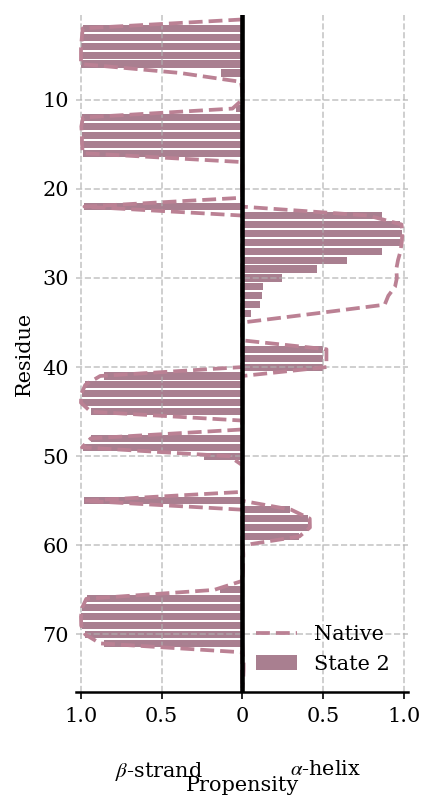

In [ ]:



# colours
COLOR_S2 = "#A97F90"
COLOR_S4 = "#C9B2BB"
COLOR_S3 = "#D9D9D9"
COLOR_N = "#BB8194"

# plot
fig, ax = plt.subplots(figsize=(3.0, 5.5))

# overlaid bars: background -> foreground
ax.barh(residues, -beta_S2, height=0.8, color=COLOR_S2, edgecolor="none", label="State 2")
ax.barh(residues,  alpha_S2, height=0.8, color=COLOR_S2, edgecolor="none")

#ax.barh(residues, -beta_S4, height=0.8, color=COLOR_S4, edgecolor="none", label="State 4")
#ax.barh(residues,  alpha_S4, height=0.8, color=COLOR_S4, edgecolor="none")

#ax.barh(residues, -beta_S3, height=0.8, color=COLOR_S3, edgecolor="none", label="State 3")
#ax.barh(residues,  alpha_S3, height=0.8, color=COLOR_S3, edgecolor="none")

# native state as dashed lines
ax.plot(-beta_N, residues, ls="--", lw=1.8, color=COLOR_N, label="Native")
ax.plot(alpha_N, residues, ls="--", lw=1.8, color=COLOR_N)

# thick central axis at x = 0
ax.axvline(0, color="k", lw=2.2)

# limits
ax.set_xlim(-1.03, 1.03)
ax.set_ylim(0.5, len(residues) + 0.5)
ax.invert_yaxis()

# y-axis label
ax.set_ylabel("Residue")

# x ticks
ax.set_xticks([-1.0, -0.5, 0.0, 0.5, 1.0])
ax.set_xticklabels(["1.0", "0.5", "0", "0.5", "1.0"])

# x-axis labels
ax.set_xlabel("Propensity", labelpad=24)

ax.text(0.25, -0.10, r"$\beta$-strand", transform=ax.transAxes, ha="center", va="top")
ax.text(0.75, -0.10, r"$\alpha$-helix", transform=ax.transAxes, ha="center", va="top")

# y ticks: every 10 residues
yticks = np.arange(0, len(residues) + 1, 10)
yticks = yticks[yticks > 0]
ax.set_yticks(yticks)
ax.set_yticklabels(yticks)

# styling
ax.spines["left"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["top"].set_visible(False)
ax.tick_params(axis="y", left=False, right=False, length=0)
ax.tick_params(axis="x", direction="out", top=False, right=False)

ax.legend(frameon=False, loc="lower right")

plt.tight_layout()
plt.savefig(outdir+'state_SS_propensities_overlay_state2.pdf')
plt.show()

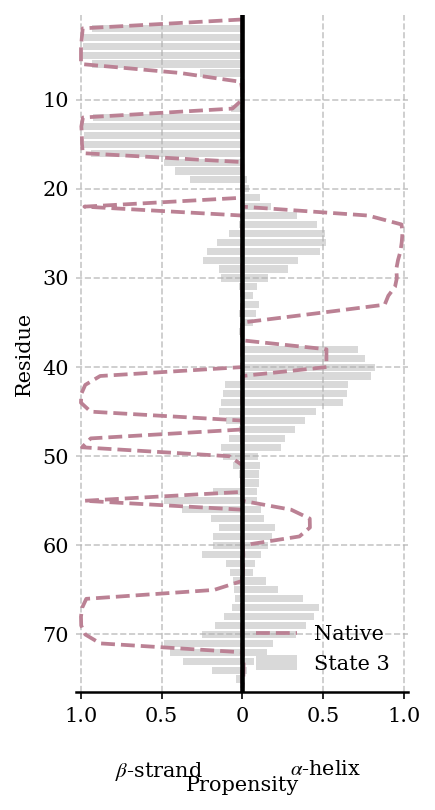

In [ ]:



# colours
COLOR_S2 = "#A97F90"
COLOR_S4 = "#C9B2BB"
COLOR_S3 = "#D9D9D9"
COLOR_N = "#BB8194"

# plot
fig, ax = plt.subplots(figsize=(3.0, 5.5))

# overlaid bars: background -> foreground
#ax.barh(residues, -beta_S2, height=0.8, color=COLOR_S2, edgecolor="none", label="State 2")
#ax.barh(residues,  alpha_S2, height=0.8, color=COLOR_S2, edgecolor="none")

#ax.barh(residues, -beta_S4, height=0.8, color=COLOR_S4, edgecolor="none", label="State 4")
#ax.barh(residues,  alpha_S4, height=0.8, color=COLOR_S4, edgecolor="none")

ax.barh(residues, -beta_S3, height=0.8, color=COLOR_S3, edgecolor="none", label="State 3")
ax.barh(residues,  alpha_S3, height=0.8, color=COLOR_S3, edgecolor="none")

# native state as dashed lines
ax.plot(-beta_N, residues, ls="--", lw=1.8, color=COLOR_N, label="Native")
ax.plot(alpha_N, residues, ls="--", lw=1.8, color=COLOR_N)

# thick central axis at x = 0
ax.axvline(0, color="k", lw=2.2)

# limits
ax.set_xlim(-1.03, 1.03)
ax.set_ylim(0.5, len(residues) + 0.5)
ax.invert_yaxis()

# y-axis label
ax.set_ylabel("Residue")

# x ticks
ax.set_xticks([-1.0, -0.5, 0.0, 0.5, 1.0])
ax.set_xticklabels(["1.0", "0.5", "0", "0.5", "1.0"])

# x-axis labels
ax.set_xlabel("Propensity", labelpad=24)

ax.text(0.25, -0.10, r"$\beta$-strand", transform=ax.transAxes, ha="center", va="top")
ax.text(0.75, -0.10, r"$\alpha$-helix", transform=ax.transAxes, ha="center", va="top")

# y ticks: every 10 residues
yticks = np.arange(0, len(residues) + 1, 10)
yticks = yticks[yticks > 0]
ax.set_yticks(yticks)
ax.set_yticklabels(yticks)

# styling
ax.spines["left"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["top"].set_visible(False)
ax.tick_params(axis="y", left=False, right=False, length=0)
ax.tick_params(axis="x", direction="out", top=False, right=False)

ax.legend(frameon=False, loc="lower right")

plt.tight_layout()
plt.savefig(outdir+'state_SS_propensities_overlay_state3.pdf')
plt.show()

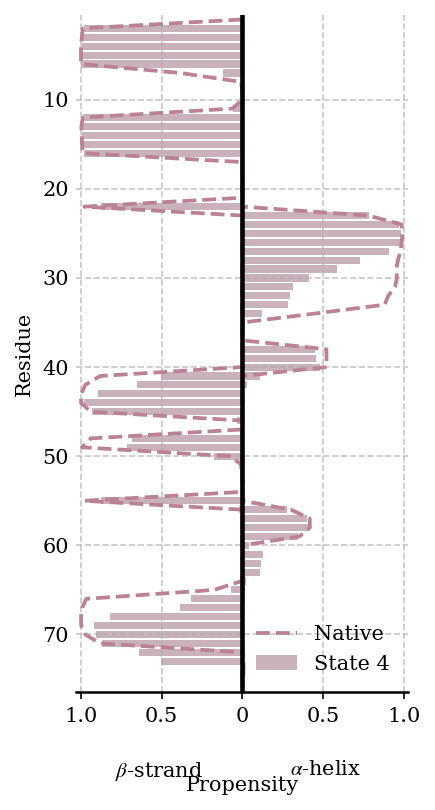

In [ ]:



# colours
COLOR_S2 = "#A97F90"
COLOR_S4 = "#C9B2BB"
COLOR_S3 = "#D9D9D9"
COLOR_N = "#BB8194"

# plot
fig, ax = plt.subplots(figsize=(3.0, 5.5))

# overlaid bars: background -> foreground
#ax.barh(residues, -beta_S2, height=0.8, color=COLOR_S2, edgecolor="none", label="State 2")
#ax.barh(residues,  alpha_S2, height=0.8, color=COLOR_S2, edgecolor="none")

ax.barh(residues, -beta_S4, height=0.8, color=COLOR_S4, edgecolor="none", label="State 4")
ax.barh(residues,  alpha_S4, height=0.8, color=COLOR_S4, edgecolor="none")

#ax.barh(residues, -beta_S3, height=0.8, color=COLOR_S3, edgecolor="none", label="State 3")
#ax.barh(residues,  alpha_S3, height=0.8, color=COLOR_S3, edgecolor="none")

# native state as dashed lines
ax.plot(-beta_N, residues, ls="--", lw=1.8, color=COLOR_N, label="Native")
ax.plot(alpha_N, residues, ls="--", lw=1.8, color=COLOR_N)

# thick central axis at x = 0
ax.axvline(0, color="k", lw=2.2)

# limits
ax.set_xlim(-1.03, 1.03)
ax.set_ylim(0.5, len(residues) + 0.5)
ax.invert_yaxis()

# y-axis label
ax.set_ylabel("Residue")

# x ticks
ax.set_xticks([-1.0, -0.5, 0.0, 0.5, 1.0])
ax.set_xticklabels(["1.0", "0.5", "0", "0.5", "1.0"])

# x-axis labels
ax.set_xlabel("Propensity", labelpad=24)

ax.text(0.25, -0.10, r"$\beta$-strand", transform=ax.transAxes, ha="center", va="top")
ax.text(0.75, -0.10, r"$\alpha$-helix", transform=ax.transAxes, ha="center", va="top")

# y ticks: every 10 residues
yticks = np.arange(0, len(residues) + 1, 10)
yticks = yticks[yticks > 0]
ax.set_yticks(yticks)
ax.set_yticklabels(yticks)

# styling
ax.spines["left"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["top"].set_visible(False)
ax.tick_params(axis="y", left=False, right=False, length=0)
ax.tick_params(axis="x", direction="out", top=False, right=False)

ax.legend(frameon=False, loc="lower right")

plt.tight_layout()
plt.savefig(outdir+'state_SS_propensities_overlay_state4.pdf')
plt.show()

In [45]:
# posterior populations of each state
pop_S2 = np.sum(wopt[mask_S2]) / np.sum(wopt)
pop_S4 = np.sum(wopt[mask_S4]) / np.sum(wopt)
pop_S3 = np.sum(wopt[mask_S3]) / np.sum(wopt)
pop_N = np.sum(wopt[mask_N]) / np.sum(wopt)

print(f'State 1 / Native: {100 * pop_N:.3f}%')
print(f'State 2:          {100 * pop_S2:.3f}%')
print(f'State 3:          {100 * pop_S3:.3f}%')
print(f'State 4:          {100 * pop_S4:.3f}%')
print(f'Total:            {100 * (pop_N + pop_S2 + pop_S3 + pop_S4):.3f}%')

State 1 / Native: 86.346%
State 2:          13.053%
State 3:          0.069%
State 4:          0.024%
Total:            99.492%


Found 1 local minima:
 1: Q = 0.734  RMSD = 0.523 nm  F = 3.847 kcal/mol


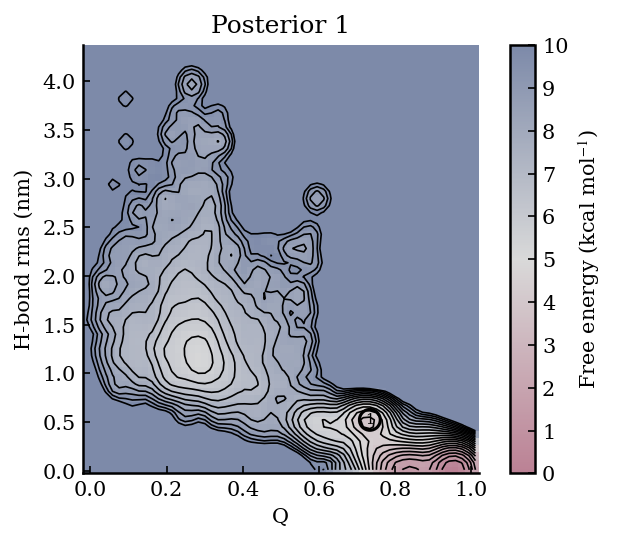

In [46]:
# now Q vs hbond res at the C-term

# FEL of posterior 1 (elbow) as a function of Q and hbond rms
# with mild Gaussian smoothing of the 2D probability histogram
# local minima are detected on the smoothed FEL and marked on the plot

from matplotlib.colors import LinearSegmentedColormap
from scipy.ndimage import gaussian_filter, minimum_filter

hbond_rms = np.load('../../DESRES_FOLDING_DATA/Ubiquitin/hbond_distance_rmsd_all_trajs.npy')

protein = proteins[0]
nbins = 60
max_energy = 10.0
sigma = 1.0
minima_neighborhood = 3
minima_max_energy = 5.0

# posterior 1 weights
wopt = np.load(f'../../{ensemble_master_dir}/{protein}/rewM14DH_scaled/log_lambda_wopt_elbow.npy')

Q_use = np.asarray(Q, dtype=float)
hbond_rms_use = np.asarray(hbond_rms, dtype=float)

# sanity check
assert len(Q_use) == len(hbond_rms_use) == len(wopt), "Q, rmsd, and wopt must have the same length"

# normalize posterior weights
w_post = wopt / np.sum(wopt)

# shared binning
xmin, xmax = np.min(Q_use), np.max(Q_use)
ymin, ymax = np.min(rmsd_use), np.max(rmsd_use)
xpad = 0.02 * (xmax - xmin)
ypad = 0.02 * (ymax - ymin)
xbins = np.linspace(xmin - xpad, xmax + xpad, nbins + 1)
ybins = np.linspace(ymin - ypad, ymax + ypad, nbins + 1)

# weighted 2D histogram
H_post, xedges, yedges = np.histogram2d(Q_use, hbond_rms_use, bins=[xbins, ybins], weights=w_post)

# smooth histogram for visualization
H_post_smooth = gaussian_filter(H_post, sigma=sigma, mode='constant', cval=0.0)
H_post_smooth = H_post_smooth / np.sum(H_post_smooth)

# convert histogram to FEL
kB = 0.0019872041
T = 303.0

def hist_to_fel(H, kB=0.0019872041, T=293.0):
    F = np.full_like(H, np.nan, dtype=float)
    mask = H > 0
    F[mask] = -kB * T * np.log(H[mask])
    F -= np.nanmin(F)
    return F

F_post = hist_to_fel(H_post_smooth, kB=kB, T=T)

# bin centers for contours
xc = 0.5 * (xedges[:-1] + xedges[1:])
yc = 0.5 * (yedges[:-1] + yedges[1:])
Xc, Yc = np.meshgrid(xc, yc, indexing='ij')

# ------------------------------------------------------------------
# identify local minima
# ------------------------------------------------------------------

F_minima = np.where(np.isfinite(F_post), F_post, np.inf)
local_min = F_minima == minimum_filter(F_minima, size=minima_neighborhood, mode='constant', cval=np.inf)
local_min &= np.isfinite(F_post)
local_min &= F_post <= minima_max_energy

# ignore outermost bins
local_min[0,:] = False
local_min[-1,:] = False
local_min[:,0] = False
local_min[:,-1] = False

# minima coordinates and energies
min_i, min_j = np.where(local_min)
min_Q = xc[min_i]
min_rmsd = yc[min_j]
min_F = F_post[min_i, min_j]

# sort minima by increasing free energy
order = np.argsort(min_F)
min_Q = min_Q[order]
min_rmsd = min_rmsd[order]
min_F = min_F[order]

print(f'Found {len(min_Q)} local minima:')

for i, (q, r, F) in enumerate(zip(min_Q, min_rmsd, min_F), start=1):
    print(f'{i:2d}: Q = {q:.3f}  RMSD = {r:.3f} nm  F = {F:.3f} kcal/mol')

# colour scale
cmap = LinearSegmentedColormap.from_list('fel_cmap', [(0.0, "#BB8194"), (0.5, "#D9D9D9"), (1.0, "#7D8AA9")])

# fill remaining NaNs with max_energy for plotting only
F_plot = np.where(np.isnan(F_post), max_energy, F_post)
F_plot = np.minimum(F_plot, max_energy)

# contour levels
levels = np.arange(0.5, max_energy + 0.001, 0.5)
levels = levels[levels <= np.nanmax(F_post)]

# plotting
fig, ax = plt.subplots(figsize=(4,3.5), constrained_layout=True)

pcm = ax.pcolormesh(xedges, yedges, F_plot.T, shading='auto', cmap=cmap, vmin=0, vmax=max_energy, rasterized=True)

if len(levels) > 0:
    ax.contour(Xc, Yc, F_post, levels=levels, linewidths=0.8, colors='black')

# mark local minima
ax.scatter(min_Q, min_rmsd, s=100, facecolors='none', edgecolors='black', linewidths=1.5, zorder=30)

# number local minima
for i, (q, r) in enumerate(zip(min_Q, min_rmsd), start=1):
    ax.text(q, r, str(i), ha='center', va='center', fontsize=7, zorder=31)

ax.set_title('Posterior 1')
ax.set_xlabel('Q')
ax.set_ylabel('H-bond rms (nm)')

ax.tick_params(axis='both', which='both', top=False, right=False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

cbar = fig.colorbar(pcm, ax=ax, pad=0.02)
cbar.set_label(r'Free energy (kcal mol$^{-1}$)')
cbar.set_ticks(np.arange(0, max_energy + 1, 1))

plt.savefig(outdir+f'{protein}_Q_hbond_rms_FEL_post1_smoothed_minima.pdf', dpi=300)
plt.show()

In [47]:
# extract representative structures for each Q-hbond rms FEL minimum
# for each minimum:
# 1) find the n_candidates closest frames in Q-hbond rms space
# 2) rank those candidates by distance from the minimum and posterior weight
# 3) select the top n_models and save them as PDB files

import os
import mdtraj as md
import numpy as np
from scipy.stats import rankdata

protein = proteins[0]
n_models = 10
n_candidates = 100

# output directory
rep_dir = 'plots_Ubq_desres/structures_Q_hbond_rms/'
os.makedirs(rep_dir, exist_ok=True)

# trajectories in exactly the same order as Q/rmsd/reweighting
trajs = sorted(find_xtc_filenames(f'../../{ensemble_master_dir}/{protein}/'))

# posterior weights
wopt = np.load(f'../../{ensemble_master_dir}/{protein}/rewM14DH_scaled/log_lambda_wopt_elbow.npy')

# use the same arrays as in the FEL
Q_use = np.asarray(Q, dtype=float)
hbond_rms_use = np.asarray(hbond_rms, dtype=float)


assert len(Q_use) == len(hbond_rms_use) == len(wopt), f"Q, RMSD, and wopt must have the same length: {len(Q_use)}, {len(rmsd_use)}, {len(wopt)}"

# normalize posterior weights
w_post = wopt / np.sum(wopt)

# ------------------------------------------------------------------
# build global frame index -> trajectory/local frame mapping
# ------------------------------------------------------------------

frame_to_traj = np.empty(len(Q_use), dtype=int)
frame_to_local = np.empty(len(Q_use), dtype=int)

global_start = 0

for traj_idx, traj in enumerate(trajs):
    traj_path = f'../../{ensemble_master_dir}/{protein}/{traj}'

    with md.open(traj_path) as f:
        n_frames = len(f)

    global_stop = global_start + n_frames

    if global_stop > len(Q_use):
        global_stop = len(Q_use)
        n_frames = global_stop - global_start

    if n_frames <= 0:
        break

    frame_to_traj[global_start:global_stop] = traj_idx
    frame_to_local[global_start:global_stop] = np.arange(n_frames)

    global_start = global_stop

    if global_start == len(Q_use):
        break

assert global_start == len(Q_use), f"Trajectory frames account for {global_start} frames, but Q/RMSD arrays contain {len(Q_use)} frames"

# ------------------------------------------------------------------
# extract representative structures for each FEL minimum
# ------------------------------------------------------------------

for imin, (minimum_Q, minimum_rmsd, minimum_F) in enumerate(zip(min_Q, min_rmsd, min_F), start=1):

    # Euclidean distance from minimum in Q-RMSD space
    distance = np.sqrt((Q_use - minimum_Q)**2 + (hbond_rms_use - minimum_rmsd)**2)

    # closest local structures
    candidates = np.argsort(distance)[:min(n_candidates, len(distance))]

    candidate_distance = distance[candidates]
    candidate_weight = w_post[candidates]

    # rank 1 = closest
    distance_rank = rankdata(candidate_distance, method='ordinal')

    # rank 1 = highest posterior weight
    weight_rank = rankdata(-candidate_weight, method='ordinal')

    # equal contribution from FEL-space distance and posterior weight
    combined_rank = distance_rank + weight_rank

    # top representative structures
    selected_local = np.argsort(combined_rank)[:min(n_models, len(candidates))]

    # output directory for this minimum
    minimum_dir = os.path.join(rep_dir, f'minimum_{imin:02d}')
    os.makedirs(minimum_dir, exist_ok=True)

    print(f'\nMinimum {imin}: Q = {minimum_Q:.3f}, RMSD = {minimum_rmsd:.3f} nm, F = {minimum_F:.3f} kcal/mol')

    info = []

    for rank, candidate_idx in enumerate(selected_local, start=1):
        global_idx = candidates[candidate_idx]
        traj_idx = frame_to_traj[global_idx]
        local_frame = frame_to_local[global_idx]
        traj = trajs[traj_idx]
        traj_path = f'../../{ensemble_master_dir}/{protein}/{traj}'

        # load selected frame
        structure = md.load_frame(traj_path, int(local_frame), top=f'../../{ensemble_master_dir}/{protein}/topology.pdb')

        # save PDB
        outfile = os.path.join(minimum_dir, f'model_{rank:02d}.pdb')
        structure.save_pdb(outfile)

        info.append([rank, global_idx, traj_idx, local_frame, Q_use[global_idx], rmsd_use[global_idx], distance[global_idx], w_post[global_idx], distance_rank[candidate_idx], weight_rank[candidate_idx], combined_rank[candidate_idx]])

        print(f'{rank:2d}: frame {global_idx:7d}  traj {traj_idx:3d}  local frame {local_frame:7d}  Q = {Q_use[global_idx]:.3f}  hbond rms = {hbond_rms_use[global_idx]:.3f}  distance = {distance[global_idx]:.4f}  weight = {w_post[global_idx]:.3e}')

    # save metadata
    np.savetxt(
        os.path.join(minimum_dir, 'models.dat'),
        np.asarray(info),
        header='rank global_frame traj_index local_frame Q hbond rms distance posterior_weight distance_rank weight_rank combined_rank',
        fmt=['%d', '%d', '%d', '%d', '%.6f', '%.6f', '%.6f', '%.8e', '%d', '%d', '%d']
    )


Minimum 1: Q = 0.734, RMSD = 0.523 nm, F = 3.847 kcal/mol
 1: frame 4003343  traj 401  local frame    7494  Q = 0.733  hbond rms = 0.523  distance = 0.0004  weight = 4.576e-07
 2: frame 4003663  traj 401  local frame    7814  Q = 0.734  hbond rms = 0.524  distance = 0.0011  weight = 5.889e-07
 3: frame 3446268  traj 345  local frame    3446  Q = 0.735  hbond rms = 0.523  distance = 0.0011  weight = 5.870e-07
 4: frame 3446024  traj 345  local frame    3202  Q = 0.733  hbond rms = 0.522  distance = 0.0010  weight = 4.098e-07
 5: frame 3449721  traj 345  local frame    6899  Q = 0.733  hbond rms = 0.522  distance = 0.0009  weight = 1.818e-07
 6: frame 4001003  traj 401  local frame    5154  Q = 0.735  hbond rms = 0.523  distance = 0.0015  weight = 2.501e-07
 7: frame 1605958  traj 160  local frame    8331  Q = 0.734  hbond rms = 0.522  distance = 0.0012  weight = 2.216e-07
 8: frame 3445703  traj 345  local frame    2881  Q = 0.732  hbond rms = 0.524  distance = 0.0012  weight = 1.770e-

State H-bond RMS range: 0.330-0.630 nm
State population: 0.22%


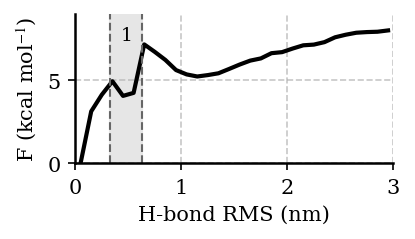

In [56]:
# 1D FEL along H-bond RMS
# zoom to H-bond RMS <= 3 nm and F <= 10 kcal/mol
# highlight the state identified from the 2D Q vs H-bond RMS FEL

nbins = 30
max_energy = 9.0
hbond_max = 3.0

k = 0.008314
T = 303.0
kT = k * T
kj_to_kcal = 0.239005736

COLOR_POST = "black"

# identified minimum from 2D FEL
state_center = 0.48

# broadened state region around the minimum
state_halfwidth = 0.15
state_low = state_center - state_halfwidth
state_high = state_center + state_halfwidth

# load data
hbond_rms = np.load('../../DESRES_FOLDING_DATA/Ubiquitin/hbond_distance_rmsd_all_trajs.npy')
w_post = np.load(f'../../{ensemble_master_dir}/{protein}/rewM14DH_scaled/log_lambda_wopt_elbow.npy')

hbond_rms_use = np.asarray(hbond_rms, dtype=float)

# sanity check
assert len(hbond_rms_use) == len(w_post), "hbond_rms and w_post must have the same length"

# restrict to plotting range
keep = np.isfinite(hbond_rms_use) & (hbond_rms_use >= 0.0) & (hbond_rms_use <= hbond_max)
hbond_plot = hbond_rms_use[keep]
w_plot = w_post[keep]

# 1D weighted histogram
bin_edges = np.linspace(0.0, hbond_max, nbins + 1)
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

counts_post, _ = np.histogram(hbond_plot, bins=bin_edges, weights=w_plot)
p_post = counts_post / np.sum(counts_post)

# convert to FEL
fel_post = np.full_like(p_post, np.nan, dtype=float)
valid = p_post > 0
fel_post[valid] = -np.log(p_post[valid]) * kT
fel_post = (fel_post - np.nanmin(fel_post)) * kj_to_kcal

# state population
mask_state = (hbond_rms_use >= state_low) & (hbond_rms_use <= state_high)
pop_state = np.sum(w_post[mask_state]) / np.sum(w_post)

print(f'State H-bond RMS range: {state_low:.3f}-{state_high:.3f} nm')
print(f'State population: {100 * pop_state:.2f}%')

# plot
fig, ax = plt.subplots(figsize=(3.0, 1.7))

ax.plot(bin_centers, fel_post, color=COLOR_POST, lw=2)

# highlight identified state
ax.axvspan(state_low, state_high, color="0.9", zorder=0)
ax.axvline(state_low, color="0.4", ls="--", lw=1)
ax.axvline(state_high, color="0.4", ls="--", lw=1)

ax.text(
    0.5 * (state_low + state_high),
    max_energy * 0.92,
    "1",
    ha="center",
    va="top",
    fontsize=9
)

ax.set_xlabel("H-bond RMS (nm)")
ax.set_ylabel(r"F (kcal mol$^{-1}$)")

ax.set_xlim(0.0, hbond_max)
ax.set_ylim(0.0, max_energy)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(direction="out", top=False, right=False)

plt.tight_layout()
plt.savefig(outdir + f'posterior1_fel_1D_hbond_rms.pdf', bbox_inches="tight")
plt.show()

State H-bond RMS range: 0.330-0.630 nm
State population: 0.69%


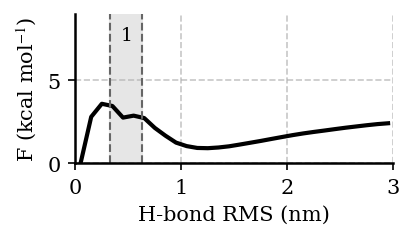

In [60]:
# 1D FEL along H-bond RMS - prior
# zoom to H-bond RMS <= 3 nm and F <= 10 kcal/mol
# highlight the state identified from the 2D Q vs H-bond RMS FEL

nbins = 30
max_energy = 9.0
hbond_max = 3.0

k = 0.008314
T = 303.0
kT = k * T
kj_to_kcal = 0.239005736

COLOR_POST = "black"

# identified minimum from 2D FEL
state_center = 0.48

# broadened state region around the minimum
state_halfwidth = 0.15
state_low = state_center - state_halfwidth
state_high = state_center + state_halfwidth

# load data
hbond_rms = np.load('../../DESRES_FOLDING_DATA/Ubiquitin/hbond_distance_rmsd_all_trajs.npy')
w_post = np.ones(hbond_rms.shape[0])/hbond_rms.shape[0]

hbond_rms_use = np.asarray(hbond_rms, dtype=float)

# sanity check
assert len(hbond_rms_use) == len(w_post), "hbond_rms and w_post must have the same length"

# restrict to plotting range
keep = np.isfinite(hbond_rms_use) & (hbond_rms_use >= 0.0) & (hbond_rms_use <= hbond_max)
hbond_plot = hbond_rms_use[keep]
w_plot = w_post[keep]

# 1D weighted histogram
bin_edges = np.linspace(0.0, hbond_max, nbins + 1)
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

counts_post, _ = np.histogram(hbond_plot, bins=bin_edges, weights=w_plot)
p_post = counts_post / np.sum(counts_post)

# convert to FEL
fel_post = np.full_like(p_post, np.nan, dtype=float)
valid = p_post > 0
fel_post[valid] = -np.log(p_post[valid]) * kT
fel_post = (fel_post - np.nanmin(fel_post)) * kj_to_kcal

# state population
mask_state = (hbond_rms_use >= state_low) & (hbond_rms_use <= state_high)
pop_state = np.sum(w_post[mask_state]) / np.sum(w_post)

print(f'State H-bond RMS range: {state_low:.3f}-{state_high:.3f} nm')
print(f'State population: {100 * pop_state:.2f}%')

# plot
fig, ax = plt.subplots(figsize=(3.0, 1.7))

ax.plot(bin_centers, fel_post, color=COLOR_POST, lw=2)

# highlight identified state
ax.axvspan(state_low, state_high, color="0.9", zorder=0)
ax.axvline(state_low, color="0.4", ls="--", lw=1)
ax.axvline(state_high, color="0.4", ls="--", lw=1)

ax.text(
    0.5 * (state_low + state_high),
    max_energy * 0.92,
    "1",
    ha="center",
    va="top",
    fontsize=9
)

ax.set_xlabel("H-bond RMS (nm)")
ax.set_ylabel(r"F (kcal mol$^{-1}$)")

ax.set_xlim(0.0, hbond_max)
ax.set_ylim(0.0, max_energy)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(direction="out", top=False, right=False)

plt.tight_layout()
plt.savefig(outdir + f'prior_fel_1D_hbond_rms.pdf', bbox_inches="tight")
plt.show()

H-bond RMS state population: 0.22%
Native state population:     86.35%


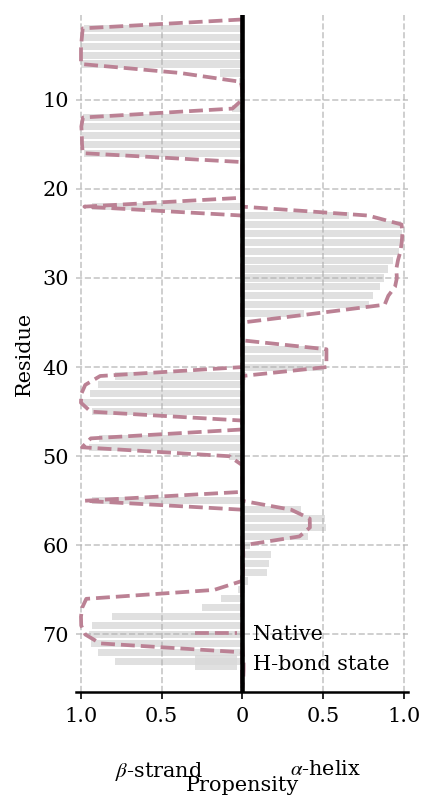

In [ ]:
# secondary-structure propensity of the H-bond-RMS state relative to the native state
# beta to the left, alpha to the right

# residue axis
residues = np.arange(1, helicity.shape[1] + 1)

# posterior weights
wopt = np.load(f'../../{ensemble_master_dir}/{protein}/rewM14DH_scaled/log_lambda_wopt_elbow.npy')

# H-bond RMS data
hbond_rms = np.load('../../DESRES_FOLDING_DATA/Ubiquitin/hbond_distance_rmsd_all_trajs.npy')

# state definitions
mask_H = (hbond_rms_use >= 0.330) & (hbond_rms_use <= 0.630)
mask_N  = (Q > 0.900) & (Q <= 1.000)   # native state = state 1

# weighted propensities
alpha_H = np.average(helicity[mask_H], axis=0, weights=wopt[mask_H])
beta_H = np.average(strand[mask_H], axis=0, weights=wopt[mask_H])

alpha_N = np.average(helicity[mask_N], axis=0, weights=wopt[mask_N])
beta_N = np.average(strand[mask_N], axis=0, weights=wopt[mask_N])

# populations
pop_H = np.sum(wopt[mask_H]) / np.sum(wopt)
pop_N = np.sum(wopt[mask_N]) / np.sum(wopt)

print(f'H-bond RMS state population: {100 * pop_H:.2f}%')
print(f'Native state population:     {100 * pop_N:.2f}%')

# colours
COLOR_H = "#D9D9D9"
COLOR_N = "#BB8194"

# plot
fig, ax = plt.subplots(figsize=(3.0, 5.5))

# H-bond RMS state as bars
ax.barh(residues, -beta_H, height=0.8, color=COLOR_H, edgecolor="none", label="H-bond state", alpha=0.8)
ax.barh(residues,  alpha_H, height=0.8, color=COLOR_H, edgecolor="none", alpha=0.8)

# native state as dashed lines
ax.plot(-beta_N, residues, ls="--", lw=1.8, color=COLOR_N, label="Native")
ax.plot(alpha_N, residues, ls="--", lw=1.8, color=COLOR_N)

# thick central axis at x = 0
ax.axvline(0, color="k", lw=2.2)

# limits
ax.set_xlim(-1.03, 1.03)
ax.set_ylim(0.5, len(residues) + 0.5)
ax.invert_yaxis()

# labels
ax.set_ylabel("Residue")

# x ticks
ax.set_xticks([-1.0, -0.5, 0.0, 0.5, 1.0])
ax.set_xticklabels(["1.0", "0.5", "0", "0.5", "1.0"])

# x-axis labels
ax.set_xlabel("Propensity", labelpad=24)
ax.text(0.25, -0.10, r"$\beta$-strand", transform=ax.transAxes, ha="center", va="top")
ax.text(0.75, -0.10, r"$\alpha$-helix", transform=ax.transAxes, ha="center", va="top")

# y ticks: every 10 residues
yticks = np.arange(0, len(residues) + 1, 10)
yticks = yticks[yticks > 0]
ax.set_yticks(yticks)
ax.set_yticklabels(yticks)

# styling
ax.spines["left"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["top"].set_visible(False)
ax.tick_params(axis="y", left=False, right=False, length=0)
ax.tick_params(axis="x", direction="out", top=False, right=False)

ax.legend(frameon=False, loc="lower right")

plt.tight_layout()
plt.savefig(outdir+'native_vs_hbond_rms_state_SS.pdf')
plt.show()

/tmp/ipykernel_1037290/2190810347.py:124: UserWarning: The following kwargs were not used by contour: 'rasterized'
  ax.contour(Xc, Yc, F_post, levels=levels, linewidths=0.8, colors='black', rasterized=True)


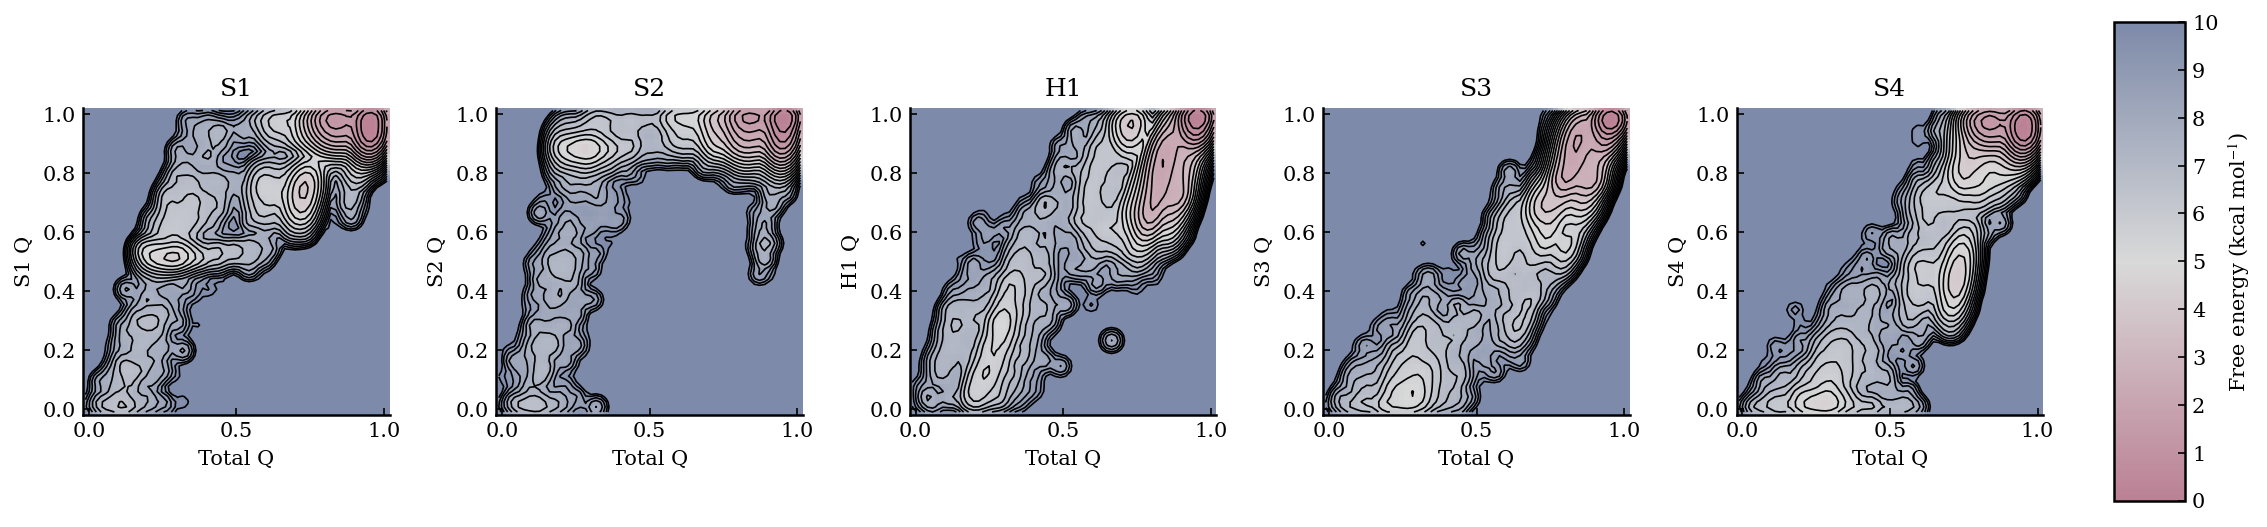

In [58]:
# FEL of posterior 1 (elbow) as a function of total Q
# and Q of strands s1-s4 and helix h1, with mild Gaussian smoothing
# Q values are first filtered using the same per-trajectory okframes
# used for reweighting so that they correspond exactly to wopt

from matplotlib.colors import LinearSegmentedColormap
from scipy.ndimage import gaussian_filter

ensemble_master_dir2 = 'DESRES_FOLDING_DATA'

protein = proteins[0]
helices = ['s1', 's2', 'h1', 's3', 's4']
synframes = 0
nbins = 60
max_energy = 10.0      # kcal mol^-1
sigma = 1.0           # Gaussian smoothing in bin units

# load total Q and helix Q values in the same trajectory order
trajs = sorted(find_xtc_filenames(f'../../{ensemble_master_dir2}/{protein}/'))

Q_total = []
Q_helices = {helix: [] for helix in helices}

for traj in trajs:
    idx = traj[4:-4]

    tmp_Q_total = np.loadtxt(f'../../{ensemble_master_dir2}/{protein}/native_contacts/Q_{traj}.txt')

    tmp_Q_helices = {}
    for helix in helices:
        tmp_Q_helices[helix] = np.loadtxt(f'../../{ensemble_master_dir2}/{protein}/native_contacts_{helix}/Q_{traj}.txt')


    Q_total.append(np.asarray(tmp_Q_total).ravel())

    for helix in helices:
        Q_helices[helix].append(np.asarray(tmp_Q_helices[helix]).ravel())

Q_total = np.concatenate(Q_total)

for helix in helices:
    Q_helices[helix] = np.concatenate(Q_helices[helix])

# posterior 1 weights
wopt = np.load(f'../../{ensemble_master_dir2}/{protein}/rewM14DH_scaled/log_lambda_wopt_elbow.npy')

# optional: drop synthetic frames at the end if present
Q_total_use = np.asarray(Q_total, dtype=float)
Q_helices_use = {helix: np.asarray(Q_helices[helix], dtype=float) for helix in helices}

if synframes > 0:
    Q_total_use = Q_total_use[:-synframes]
    for helix in helices:
        Q_helices_use[helix] = Q_helices_use[helix][:-synframes]
    wopt = wopt[:-synframes]

# sanity checks
for helix in helices:
    assert len(Q_total_use) == len(Q_helices_use[helix]) == len(wopt), f"Total Q, {helix} Q, and wopt must have the same length: {len(Q_total_use)}, {len(Q_helices_use[helix])}, {len(wopt)}"

# normalize posterior weights
w_post = wopt / np.sum(wopt)

# total-Q binning shared by all panels
xmin, xmax = np.min(Q_total_use), np.max(Q_total_use)
xpad = 0.02 * (xmax - xmin)
xbins = np.linspace(xmin - xpad, xmax + xpad, nbins + 1)

# thermodynamic constants
kB = 0.0019872041  # kcal mol^-1 K^-1
T = 303.0

def hist_to_fel(H, kB=0.0019872041, T=293.0):
    F = np.full_like(H, np.nan, dtype=float)
    mask = H > 0
    F[mask] = -kB * T * np.log(H[mask])
    F -= np.nanmin(F)
    return F

# colour scale
cmap = LinearSegmentedColormap.from_list('fel_cmap', [(0.0, "#BB8194"), (0.5, "#D9D9D9"), (1.0, "#7D8AA9")])

# plot
fig, axes = plt.subplots(1, 5, figsize=(15.0, 3.4), constrained_layout=True)

pcm = None

for ax, helix in zip(axes, helices):

    Q_helix_use = Q_helices_use[helix]

    # helix-specific y binning
    ymin, ymax = np.min(Q_helix_use), np.max(Q_helix_use)
    ypad = 0.02 * (ymax - ymin)
    ybins = np.linspace(ymin - ypad, ymax + ypad, nbins + 1)

    # weighted 2D histogram
    H_post, xedges, yedges = np.histogram2d(Q_total_use, Q_helix_use, bins=[xbins, ybins], weights=w_post)

    # smooth histogram
    H_post_smooth = gaussian_filter(H_post, sigma=sigma, mode='constant', cval=0.0)
    H_post_smooth = H_post_smooth / np.sum(H_post_smooth)

    # convert histogram to FEL
    F_post = hist_to_fel(H_post_smooth, kB=kB, T=T)

    # bin centers for contours
    xc = 0.5 * (xedges[:-1] + xedges[1:])
    yc = 0.5 * (yedges[:-1] + yedges[1:])
    Xc, Yc = np.meshgrid(xc, yc, indexing='ij')

    # fill remaining NaNs with max_energy for plotting only
    F_plot = np.where(np.isnan(F_post), max_energy, F_post)
    F_plot = np.minimum(F_plot, max_energy)

    # contour levels
    levels = np.arange(0.5, max_energy + 0.001, 0.5)
    levels = levels[levels <= np.nanmax(F_post)]

    # FEL
    pcm = ax.pcolormesh(xedges, yedges, F_plot.T, shading='auto', cmap=cmap, vmin=0, vmax=max_energy, rasterized=True)

    if len(levels) > 0:
        ax.contour(Xc, Yc, F_post, levels=levels, linewidths=0.8, colors='black', rasterized=True)

    ax.set_title(helix.upper())
    ax.set_xlabel('Total Q')
    ax.set_ylabel(f'{helix.upper()} Q')

    ax.set_box_aspect(1)

    ax.tick_params(axis='both', which='both', top=False, right=False)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# single shared, thinner colourbar
cbar = fig.colorbar(pcm, ax=axes, pad=0.02, fraction=0.025, aspect=30)
cbar.set_label(r'Free energy (kcal mol$^{-1}$)')
cbar.set_ticks(np.arange(0, max_energy + 1, 1))

plt.savefig(outdir+f'{protein}_Q_h1-h4_Q_FEL_posterior1_smoothed_{ensemble_master_dir2}.pdf', dpi=300)
plt.show()

/tmp/ipykernel_1037290/1534010168.py:123: UserWarning: The following kwargs were not used by contour: 'rasterized'
  ax.contour(Xc, Yc, F_post, levels=levels, linewidths=0.8, colors='black', rasterized=True)


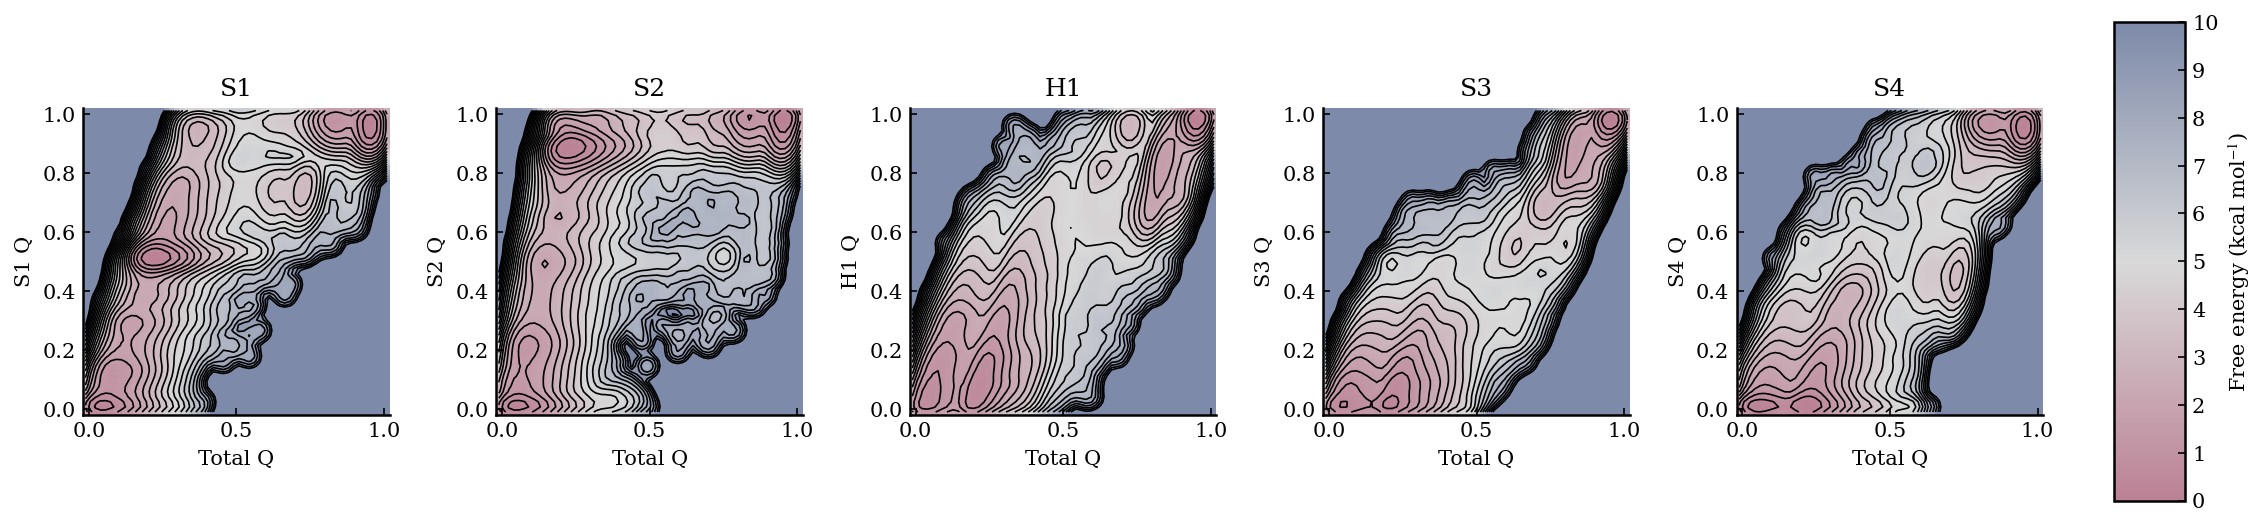

In [59]:
# FEL of prior as a function of total Q
# and Q of strands s1-s4 and helix h1, with mild Gaussian smoothing
# Q values are first filtered using the same per-trajectory okframes
# used for reweighting so that they correspond exactly to wopt

from matplotlib.colors import LinearSegmentedColormap
from scipy.ndimage import gaussian_filter

ensemble_master_dir2 = 'DESRES_FOLDING_DATA'

protein = proteins[0]
helices = ['s1', 's2', 'h1', 's3', 's4']
synframes = 0
nbins = 60
max_energy = 10.0      # kcal mol^-1
sigma = 1.0           # Gaussian smoothing in bin units

# load total Q and helix Q values in the same trajectory order
trajs = sorted(find_xtc_filenames(f'../../{ensemble_master_dir2}/{protein}/'))

Q_total = []
Q_helices = {helix: [] for helix in helices}

for traj in trajs:
    idx = traj[4:-4]

    tmp_Q_total = np.loadtxt(f'../../{ensemble_master_dir2}/{protein}/native_contacts/Q_{traj}.txt')

    tmp_Q_helices = {}
    for helix in helices:
        tmp_Q_helices[helix] = np.loadtxt(f'../../{ensemble_master_dir2}/{protein}/native_contacts_{helix}/Q_{traj}.txt')

    Q_total.append(np.asarray(tmp_Q_total).ravel())

    for helix in helices:
        Q_helices[helix].append(np.asarray(tmp_Q_helices[helix]).ravel())

Q_total = np.concatenate(Q_total)

for helix in helices:
    Q_helices[helix] = np.concatenate(Q_helices[helix])

# prior weights
wopt = np.ones(Q_total.shape[0])/Q_total.shape[0]

# optional: drop synthetic frames at the end if present
Q_total_use = np.asarray(Q_total, dtype=float)
Q_helices_use = {helix: np.asarray(Q_helices[helix], dtype=float) for helix in helices}

if synframes > 0:
    Q_total_use = Q_total_use[:-synframes]
    for helix in helices:
        Q_helices_use[helix] = Q_helices_use[helix][:-synframes]
    wopt = wopt[:-synframes]

# sanity checks
for helix in helices:
    assert len(Q_total_use) == len(Q_helices_use[helix]) == len(wopt), f"Total Q, {helix} Q, and wopt must have the same length: {len(Q_total_use)}, {len(Q_helices_use[helix])}, {len(wopt)}"

# normalize posterior weights
w_post = wopt / np.sum(wopt)

# total-Q binning shared by all panels
xmin, xmax = np.min(Q_total_use), np.max(Q_total_use)
xpad = 0.02 * (xmax - xmin)
xbins = np.linspace(xmin - xpad, xmax + xpad, nbins + 1)

# thermodynamic constants
kB = 0.0019872041  # kcal mol^-1 K^-1
T = 303.0

def hist_to_fel(H, kB=0.0019872041, T=293.0):
    F = np.full_like(H, np.nan, dtype=float)
    mask = H > 0
    F[mask] = -kB * T * np.log(H[mask])
    F -= np.nanmin(F)
    return F

# colour scale
cmap = LinearSegmentedColormap.from_list('fel_cmap', [(0.0, "#BB8194"), (0.5, "#D9D9D9"), (1.0, "#7D8AA9")])

# plot
fig, axes = plt.subplots(1, 5, figsize=(15.0, 3.4), constrained_layout=True)

pcm = None

for ax, helix in zip(axes, helices):

    Q_helix_use = Q_helices_use[helix]

    # helix-specific y binning
    ymin, ymax = np.min(Q_helix_use), np.max(Q_helix_use)
    ypad = 0.02 * (ymax - ymin)
    ybins = np.linspace(ymin - ypad, ymax + ypad, nbins + 1)

    # weighted 2D histogram
    H_post, xedges, yedges = np.histogram2d(Q_total_use, Q_helix_use, bins=[xbins, ybins], weights=w_post)

    # smooth histogram
    H_post_smooth = gaussian_filter(H_post, sigma=sigma, mode='constant', cval=0.0)
    H_post_smooth = H_post_smooth / np.sum(H_post_smooth)

    # convert histogram to FEL
    F_post = hist_to_fel(H_post_smooth, kB=kB, T=T)

    # bin centers for contours
    xc = 0.5 * (xedges[:-1] + xedges[1:])
    yc = 0.5 * (yedges[:-1] + yedges[1:])
    Xc, Yc = np.meshgrid(xc, yc, indexing='ij')

    # fill remaining NaNs with max_energy for plotting only
    F_plot = np.where(np.isnan(F_post), max_energy, F_post)
    F_plot = np.minimum(F_plot, max_energy)

    # contour levels
    levels = np.arange(0.5, max_energy + 0.001, 0.5)
    levels = levels[levels <= np.nanmax(F_post)]

    # FEL
    pcm = ax.pcolormesh(xedges, yedges, F_plot.T, shading='auto', cmap=cmap, vmin=0, vmax=max_energy, rasterized=True)

    if len(levels) > 0:
        ax.contour(Xc, Yc, F_post, levels=levels, linewidths=0.8, colors='black', rasterized=True)

    ax.set_title(helix.upper())
    ax.set_xlabel('Total Q')
    ax.set_ylabel(f'{helix.upper()} Q')

    ax.set_box_aspect(1)

    ax.tick_params(axis='both', which='both', top=False, right=False)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# single shared, thinner colourbar
cbar = fig.colorbar(pcm, ax=axes, pad=0.02, fraction=0.025, aspect=30)
cbar.set_label(r'Free energy (kcal mol$^{-1}$)')
cbar.set_ticks(np.arange(0, max_energy + 1, 1))

plt.savefig(outdir+f'{protein}_Q_h1-h4_Q_FEL_prior_smoothed_{ensemble_master_dir2}.pdf', dpi=300)
plt.show()